# CASMI 2026 : analyse exploratoire des données

**Objectif du notebook** : comprendre en profondeur le jeu de données *Enveda CASMI 2026* (spectres MS/MS vers structure moléculaire) avant tout travail de modélisation. Pour chaque graphique, on indique **la question posée**, **ce qu'on observe** et **ce que cela implique pour le feature engineering**.

| | |
|---|---|
| **Tâche** | Pour chaque `molecule_id` de test, proposer jusqu'à **25 SMILES** classés |
| **Métrique** | **MRR@25** : 1/rang de la première bonne structure (0 si absente) |
| **Critère de correction** | même **InChIKey14** (connectivité 2D, stéréo et tautomères ignorés) |

**Plan**
1. Chargement et architecture des fichiers
2. Qualité des données : valeurs manquantes et aberrantes
3. Les sources du train et leur hétérogénéité
4. Granularité : spectres par molécule
5. Ion précurseur, adduits et masse neutre
6. Énergie de collision et instruments
7. Anatomie des spectres MS2 (pics, intensités, bruit)
8. Features spectrales dérivées (entropie, précurseur résiduel, pertes de neutres)
9. Espace chimique des cibles (RDKit)
10. Ambiguïté isomérique et espace de recherche
11. Domain shift train/test dans l'espace des spectres
12. Synthèse et implications pour le feature engineering

In [3]:
import warnings, re, os
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import polars as pl
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap

pl.Config.set_tbl_rows(25); pl.Config.set_tbl_cols(20); pl.Config.set_tbl_width_chars(160); pl.Config.set_fmt_str_lengths(60)

DATA  = Path("enveda-CASMI26-molecule-id-mass-spectra (1)")
CACHE = Path("cache"); CACHE.mkdir(exist_ok=True)
SEED  = 42

In [4]:
# --- Style graphique : surfaces sobres, axes discrets, palette fixe par groupe ---
INK, INK2, MUTED, GRID, AXIS, SURF = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "figure.dpi": 110, "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Arial", "DejaVu Sans"],
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "lines.linewidth": 2,
})

# Une couleur = un groupe, identique dans TOUT le notebook.
# Le test est en encre noire : c'est la référence à laquelle on compare tout le reste.
GROUPS = ["Test", "enveda-180", "enveda-np-examples", "Publiques"]
COL = {"Test": INK, "enveda-180": "#2a78d6", "enveda-np-examples": "#1baf7a", "Publiques": "#eb6834"}
SEQ = LinearSegmentedColormap.from_list("blue_seq", ["#f4f8fd", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])

def lib_group(col="ingest_lib"):
    # Regroupe les 11 bibliothèques en 3 familles (le test est ajouté à part)
    return (pl.when(pl.col(col) == "enveda-180").then(pl.lit("enveda-180"))
              .when(pl.col(col) == "enveda-np-examples").then(pl.lit("enveda-np-examples"))
              .otherwise(pl.lit("Publiques")).alias("group"))

def fmt_thousands(ax, axis="x"):
    f = mticker.FuncFormatter(lambda v, _: f"{v/1e6:.1f} M" if v >= 1e6 else (f"{v/1e3:.0f} k" if v >= 1e3 else f"{v:.0f}"))
    (ax.xaxis if axis == "x" else ax.yaxis).set_major_formatter(f)

## 1. Chargement et architecture des fichiers

`train.parquet` pèse **2,8 Go** pour 2,5 M lignes. L'essentiel du volume vient des deux colonnes-listes (`ms2_mzs`, `ms2_normalized_intensities`). Stratégie :
- **colonnes scalaires du train** : chargées en entier (quelques centaines de Mo) ;
- **spectres du train** : **échantillon stratifié de 3 %** tiré *row group* par *row group*, plus **la totalité** de `enveda-np-examples` (le seul jeu de produits naturels sur plateforme timsTOF) ;
- **test** : chargé en entier (1 213 spectres).

L'échantillon est mis en cache dans `cache/` pour que le notebook se relance vite.

In [5]:
pf = pq.ParquetFile(DATA / "train.parquet")
print(pf.schema_arrow)
print(f"\n{pf.metadata.num_rows:,} lignes | {pf.metadata.num_row_groups} row groups")

ingest_lib: string
normalized_smiles: string
inchikey: string
inchikey14: string
molecular_formula: string
ionization_mode: string
instrument_type: string
adduct: string
adduct_orig: string
precursor_mz: double
precursor_error_ppm: double
ms2_mzs: list<element: double>
  child 0, element: double
ms2_normalized_intensities: list<element: double>
  child 0, element: double
num_peaks: int64
base_peak_intensity: double
collision_energy_ev: list<element: double>
  child 0, element: double
collision_energy_orig: string
collision_energy_orig_units: string

2,539,608 lignes | 21 row groups


In [6]:
SCALAR = ["ingest_lib", "normalized_smiles", "inchikey", "inchikey14", "molecular_formula",
          "ionization_mode", "instrument_type", "adduct", "adduct_orig", "precursor_mz",
          "precursor_error_ppm", "num_peaks", "base_peak_intensity",
          "collision_energy_orig", "collision_energy_orig_units"]

f_meta = CACHE / "train_meta.parquet"
if not f_meta.exists():
    pl.read_parquet(DATA / "train.parquet", columns=SCALAR + ["collision_energy_ev"]).write_parquet(f_meta)
meta = pl.read_parquet(f_meta).with_columns(lib_group())

f_spec = CACHE / "train_spectra_sample.parquet"
if not f_spec.exists():
    parts = []
    for i in range(pf.num_row_groups):
        rg = pl.from_arrow(pf.read_row_group(i))
        np_ex = rg.filter(pl.col("ingest_lib") == "enveda-np-examples")       # on garde tout
        other = rg.filter(pl.col("ingest_lib") != "enveda-np-examples")
        parts += [np_ex, other.sample(fraction=0.03, seed=SEED + i)]
    pl.concat(parts).write_parquet(f_spec)
spec = pl.read_parquet(f_spec).with_columns(lib_group())

test = pl.read_parquet(DATA / "test.parquet").with_columns(pl.lit("Test").alias("group"), pl.lit("test").alias("ingest_lib"))
sub  = pl.read_csv(DATA / "sample_submission.csv")

print(f"meta  : {meta.shape}\nspec  : {spec.shape}  (échantillon de spectres du train)\ntest  : {test.shape}\nsubm. : {sub.shape}")

meta  : (2539608, 17)
spec  : (77333, 19)  (échantillon de spectres du train)
test  : (1213, 14)
subm. : (400, 2)


In [7]:
# Organisation physique : quelles sources dans quels row groups ? (utile pour lire par morceaux)
rg_rows = []
for i in range(pf.num_row_groups):
    libs = pl.from_arrow(pf.read_row_group(i, columns=["ingest_lib"]))["ingest_lib"].value_counts(sort=True)
    rg_rows.append({"row_group": i, "n": int(libs["count"].sum()),
                    "sources": ", ".join(f"{l} ({c:,})" for l, c in libs.iter_rows())})
pl.DataFrame(rg_rows)

row_group,n,sources
i64,i64,str
0,131072,"""enveda-180 (128,527), drug_plus (2,545)"""
1,131072,"""enveda-180 (131,072)"""
2,131072,"""enveda-180 (131,072)"""
3,131072,"""enveda-180 (131,072)"""
4,131072,"""enveda-180 (131,072)"""
5,131072,"""enveda-180 (131,072)"""
6,131072,"""enveda-180 (131,072)"""
7,131072,"""enveda-180 (131,072)"""
8,131072,"""enveda-180 (107,754), gnps (23,318)"""


**Comparaison des colonnes train/test.** Le test ne contient que les **entrées** observables. Les colonnes `normalized_smiles`, `inchikey(14)`, `molecular_formula`, `precursor_error_ppm` et `ingest_lib` n'existent qu'en train : la formule brute et l'erreur ppm sont calculées *à partir de la vraie structure*, elles ne peuvent donc pas servir de features.

In [8]:
cols_train, cols_test = set(pf.schema_arrow.names), set(test.columns) - {"group", "ingest_lib"}
rows = []
for c in sorted(cols_train | cols_test):
    dt = str(pf.schema_arrow.field(c).type) if c in cols_train else str(test.schema[c])
    rows.append({"colonne": c, "type": dt, "train": c in cols_train, "test": c in cols_test})
pl.DataFrame(rows).sort(["test", "train"], descending=True)

colonne,type,train,test
str,str,bool,bool
"""adduct""","""string""",true,true
"""base_peak_intensity""","""double""",true,true
"""collision_energy_ev""","""list<element: double>""",true,true
"""collision_energy_orig""","""string""",true,true
"""collision_energy_orig_units""","""string""",true,true
"""instrument_type""","""string""",true,true
"""ionization_mode""","""string""",true,true
"""ms2_mzs""","""list<element: double>""",true,true
"""ms2_normalized_intensities""","""list<element: double>""",true,true


In [9]:
# Une ligne = un spectre. Exemple de molécule de test avec ses spectres :
ex_id = test.group_by("molecule_id").len().filter(pl.col("len") == 4)["molecule_id"].sort()[0]
test.filter(pl.col("molecule_id") == ex_id).with_columns(
    pl.col("ms2_mzs").list.len().alias("n_pics")
).select(["molecule_id", "spectrum_id", "adduct", "precursor_mz", "collision_energy_orig", "collision_energy_ev", "n_pics", "base_peak_intensity"])

molecule_id,spectrum_id,adduct,precursor_mz,collision_energy_orig,collision_energy_ev,n_pics,base_peak_intensity
str,str,str,f64,str,list[f64],u32,f64
"""m_005e53""","""s_4d19d522""","""[M+H]+""",375.0709,"""20,40,60""","[20.0, 40.0, 60.0]",183,2.711324e6
"""m_005e53""","""s_5b6e28ff""","""[M+H]+""",375.0709,"""40""",[40.0],119,1.512428e6
"""m_005e53""","""s_6e514292""","""[M+H]+""",375.0709,"""60""",[60.0],84,989677.0
"""m_005e53""","""s_855ae19c""","""[M-H]-""",373.0562,"""-60""",[60.0],33,6295.0


In [10]:
print(sub.head(3))
print("\nCandidats par ligne :", sub["smiles"].str.split(";").list.len().unique().to_list())

shape: (3, 2)
┌─────────────┬───────────────────────────────────────────────────────────────┐
│ molecule_id ┆ smiles                                                        │
│ ---         ┆ ---                                                           │
│ str         ┆ str                                                           │
╞═════════════╪═══════════════════════════════════════════════════════════════╡
│ m_005e53    ┆ CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;… │
│ m_006153    ┆ CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;… │
│ m_00b5aa    ┆ CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;CCO;… │
└─────────────┴───────────────────────────────────────────────────────────────┘

Candidats par ligne : [25]


## 2. Qualité des données : valeurs manquantes

**Question** : quelles colonnes sont incomplètes, et ces manques sont-ils aléatoires ou structurés par source ?

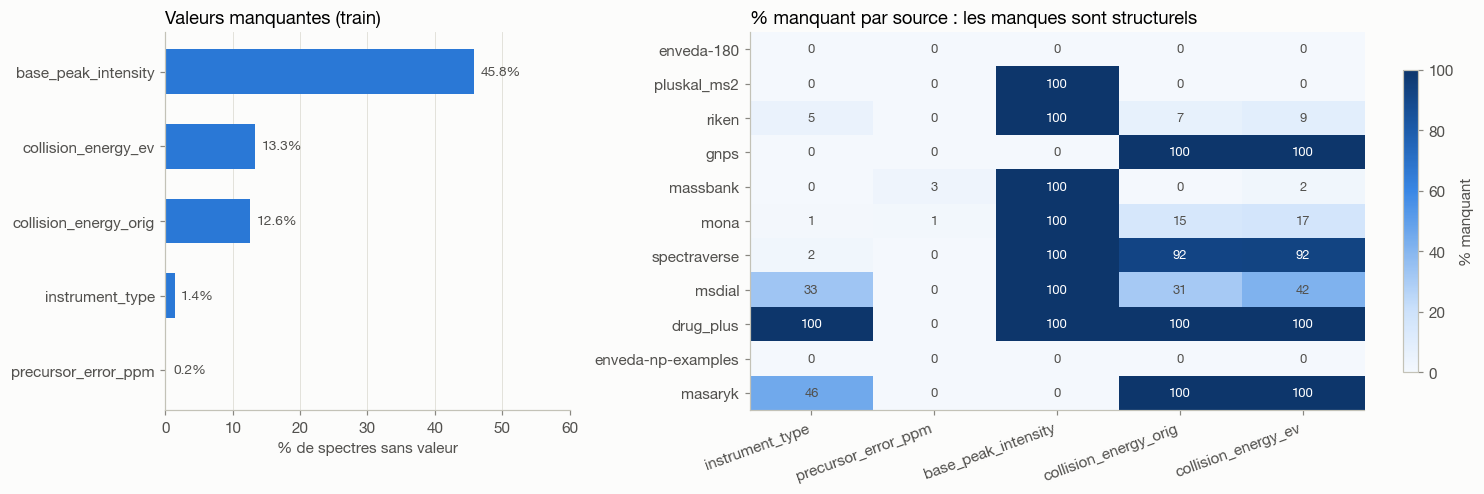

Test : valeurs manquantes = 0


In [11]:
miss_cols = ["instrument_type", "precursor_error_ppm", "base_peak_intensity", "collision_energy_orig", "collision_energy_ev"]
# Les "valeurs manquantes déguisées" : chaînes vides, 'nan', 'N/A', listes vides, unité 'unknown'
mm = meta.with_columns(
    (pl.col("instrument_type").is_null() | pl.col("instrument_type").str.to_lowercase().is_in(["", "nan", "n/a"])).alias("instrument_type"),
    pl.col("precursor_error_ppm").is_null().alias("precursor_error_ppm"),
    pl.col("base_peak_intensity").is_null().alias("base_peak_intensity"),
    pl.col("collision_energy_orig").is_null().alias("collision_energy_orig"),
    (pl.col("collision_energy_ev").list.len().fill_null(0) == 0).alias("collision_energy_ev"),
)
by_lib = mm.group_by("ingest_lib").agg([pl.col(c).mean() for c in miss_cols] + [pl.len()]).sort("len", descending=True)

fig, (a0, a1) = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.9]})
glob = mm.select([pl.col(c).mean() for c in miss_cols]).row(0)
order = np.argsort(glob)
a0.barh(np.array(miss_cols)[order], np.array(glob)[order] * 100, color=COL["enveda-180"], height=0.6)
for y, v in enumerate(np.array(glob)[order]):
    a0.text(v * 100 + 1, y, f"{v:.1%}", va="center", color=INK2, fontsize=9)
a0.set_xlabel("% de spectres sans valeur"); a0.set_title("Valeurs manquantes (train)"); a0.set_xlim(0, 60); a0.grid(axis="y", visible=False)

M = by_lib.select(miss_cols).to_numpy() * 100
im = a1.imshow(M, cmap=SEQ, vmin=0, vmax=100, aspect="auto")
a1.set_xticks(range(len(miss_cols)), miss_cols, rotation=20, ha="right"); a1.set_yticks(range(len(by_lib)), by_lib["ingest_lib"])
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        a1.text(j, i, f"{M[i,j]:.0f}", ha="center", va="center", fontsize=8.5, color="white" if M[i, j] > 55 else INK2)
a1.grid(False); a1.set_title("% manquant par source : les manques sont structurels")
fig.colorbar(im, ax=a1, shrink=0.8, label="% manquant")
plt.tight_layout(); plt.show()

print("Test : valeurs manquantes =", test.null_count().sum_horizontal()[0])

**Ce qu'on retient**
- Les manques **ne sont pas aléatoires** : ils dépendent de la source. `base_peak_intensity` n'existe que pour les données Enveda, gnps et masaryk. L'énergie de collision est inconnue pour presque toute la partie gnps, spectraverse, msdial et drug_plus.
- Le **test est complet**. Une feature comme « intensité absolue présente/absente » dirait seulement d'où vient le spectre, ce qui est un **raccourci (leakage de source)** inutile en test.
- `collision_energy_ev` vide doit être encodé explicitement (`ce_missing=1`) plutôt qu'imputé arbitrairement.

## 3. Les sources du train : un assemblage hétérogène

**Question** : d'où viennent les spectres, combien de molécules distinctes apporte chaque source, et laquelle ressemble au test ?

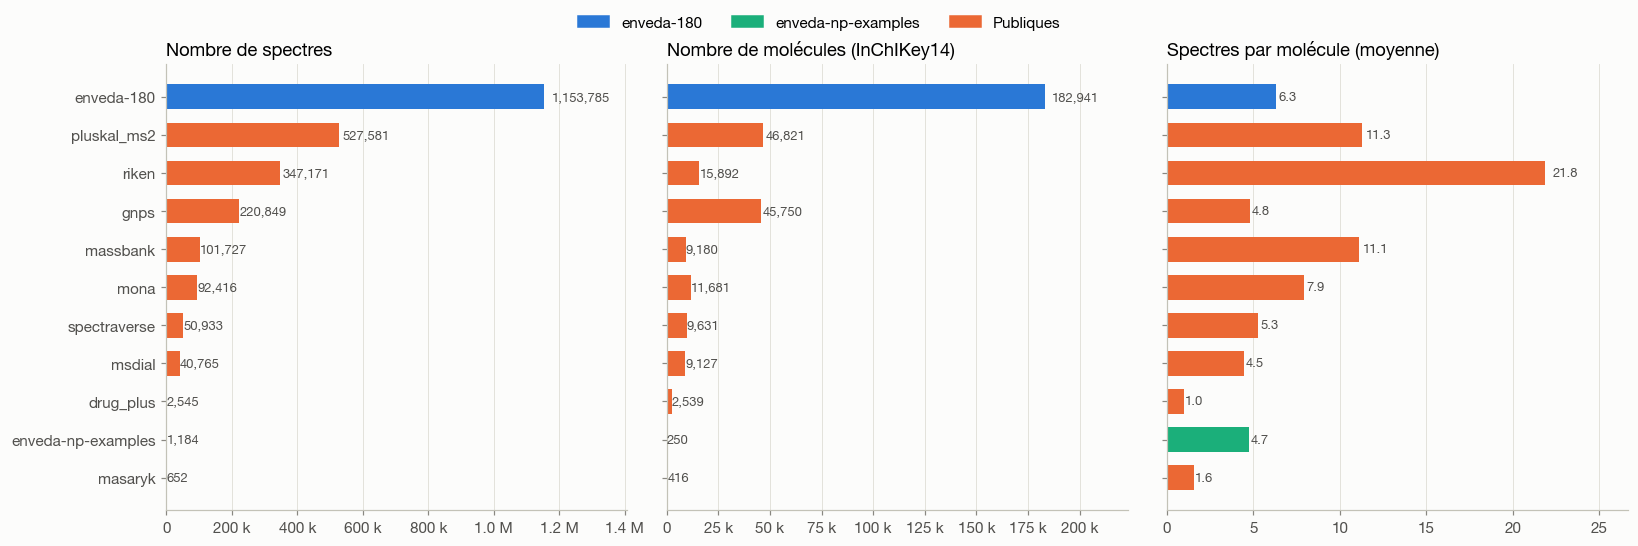

Total : 2,539,608 spectres, 275,810 molécules uniques


In [12]:
src = (meta.group_by("ingest_lib", "group")
           .agg(pl.len().alias("spectres"), pl.col("inchikey14").n_unique().alias("molecules"))
           .with_columns((pl.col("spectres") / pl.col("molecules")).alias("spectres_par_mol"))
           .sort("spectres"))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
for ax, c, t in zip(axes, ["spectres", "molecules", "spectres_par_mol"], ["Nombre de spectres", "Nombre de molécules (InChIKey14)", "Spectres par molécule (moyenne)"]):
    ax.barh(src["ingest_lib"], src[c], color=[COL[g] for g in src["group"]], height=0.65)
    for y, v in enumerate(src[c]):
        ax.text(v * 1.02, y, f"{v:,.0f}" if c != "spectres_par_mol" else f"{v:.1f}", va="center", fontsize=8.5, color=INK2)
    ax.set_title(t); ax.grid(axis="y", visible=False)
    if c != "spectres_par_mol": fmt_thousands(ax)
    ax.set_xlim(0, src[c].max() * 1.22)
handles = [plt.Rectangle((0, 0), 1, 1, color=COL[g]) for g in GROUPS[1:]]
fig.legend(handles, GROUPS[1:], loc="upper center", ncol=3, bbox_to_anchor=(0.5, 1.04))
plt.tight_layout(); plt.show()

tot = meta.select(pl.len(), pl.col("inchikey14").n_unique()).row(0)
print(f"Total : {tot[0]:,} spectres, {tot[1]:,} molécules uniques")

In [13]:
# Recouvrement des molécules entre familles de sources
fam = meta.group_by("inchikey14").agg(pl.col("group").unique().sort().alias("fams"))
fam = fam.with_columns(pl.col("fams").list.join(" + ").alias("combo"))
fam["combo"].value_counts(sort=True)

combo,count
str,u32
"""enveda-180""",180653
"""Publiques""",92619
"""Publiques + enveda-180""",2288
"""Publiques + enveda-np-examples""",250


**Ce qu'on retient**
- **enveda-180** domine : 45 % des spectres et **2/3 des molécules**. Il a peu de recouvrement avec les bibliothèques publiques, ce sont donc des molécules **nouvelles** (chimiothèque synthétique).
- Les bibliothèques publiques (pluskal, riken, gnps, etc.) apportent ~93 k molécules, souvent avec **beaucoup de spectres par molécule** (riken : ~22). Ce sont des énergies et adduits multiples, avec un **risque de surpondérer** quelques molécules.
- **enveda-np-examples** ne compte que 250 molécules : même plateforme que le test, mais des produits naturels. On verra (sections 8 à 11) que **le test ressemble finalement davantage à enveda-180** qu'à ces exemples.

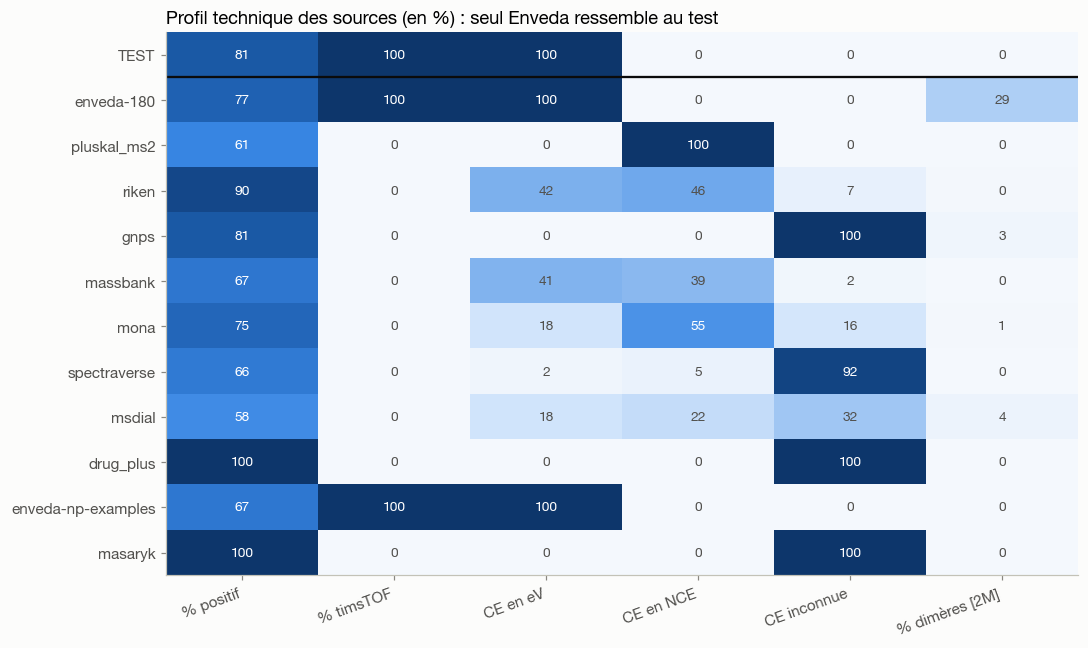

In [14]:
# Profil "technique" de chaque source : polarité, instrument timsTOF, unités CE
prof = (meta.group_by("ingest_lib").agg(
            (pl.col("ionization_mode") == "positive").mean().alias("% positif"),
            (pl.col("instrument_type") == "timsTOF").mean().alias("% timsTOF"),
            (pl.col("collision_energy_orig_units") == "eV").mean().alias("CE en eV"),
            (pl.col("collision_energy_orig_units") == "NCE").mean().alias("CE en NCE"),
            (pl.col("collision_energy_orig_units") == "unknown").mean().alias("CE inconnue"),
            pl.col("adduct").str.starts_with("[2M").mean().alias("% dimères [2M]"),
            pl.len().alias("n"))
        .sort("n", descending=True))
tprof = test.select((pl.col("ionization_mode") == "positive").mean().alias("% positif"),
                    (pl.col("instrument_type") == "timsTOF").mean().alias("% timsTOF"),
                    (pl.col("collision_energy_orig_units") == "eV").mean().alias("CE en eV"),
                    (pl.col("collision_energy_orig_units") == "NCE").mean().alias("CE en NCE"),
                    (pl.col("collision_energy_orig_units") == "unknown").mean().alias("CE inconnue"),
                    pl.col("adduct").str.starts_with("[2M").mean().alias("% dimères [2M]"))
cols = tprof.columns
M = np.vstack([tprof.to_numpy(), prof.select(cols).to_numpy()]) * 100
labels = ["TEST"] + prof["ingest_lib"].to_list()

fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(M, cmap=SEQ, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(cols)), cols, rotation=20, ha="right"); ax.set_yticks(range(len(labels)), labels)
ax.get_yticklabels()[0].set_fontweight("bold")
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j, i, f"{M[i,j]:.0f}", ha="center", va="center", fontsize=9, color="white" if M[i, j] > 55 else INK2)
ax.axhline(0.5, color=INK, lw=1.5); ax.grid(False)
ax.set_title("Profil technique des sources (en %) : seul Enveda ressemble au test")
plt.tight_layout(); plt.show()

**Ce qu'on retient** : le test est 100 % timsTOF avec des énergies en eV, sans aucun dimère. Seules **enveda-180** et **enveda-np-examples** partagent cette signature. Les autres sources viennent d'Orbitrap ou de QTOF variés, avec des énergies de collision dans d'autres unités. Leurs spectres sont **valides physiquement mais décalés en distribution**, ce qui pourra justifier une **pondération par source** ou une feature `instrument_group`.

## 4. Granularité : combien de spectres par molécule ?

**Question** : l'unité de prédiction est la molécule, mais la ligne est un spectre. Comment se répartissent les spectres par molécule dans le train et le test ?

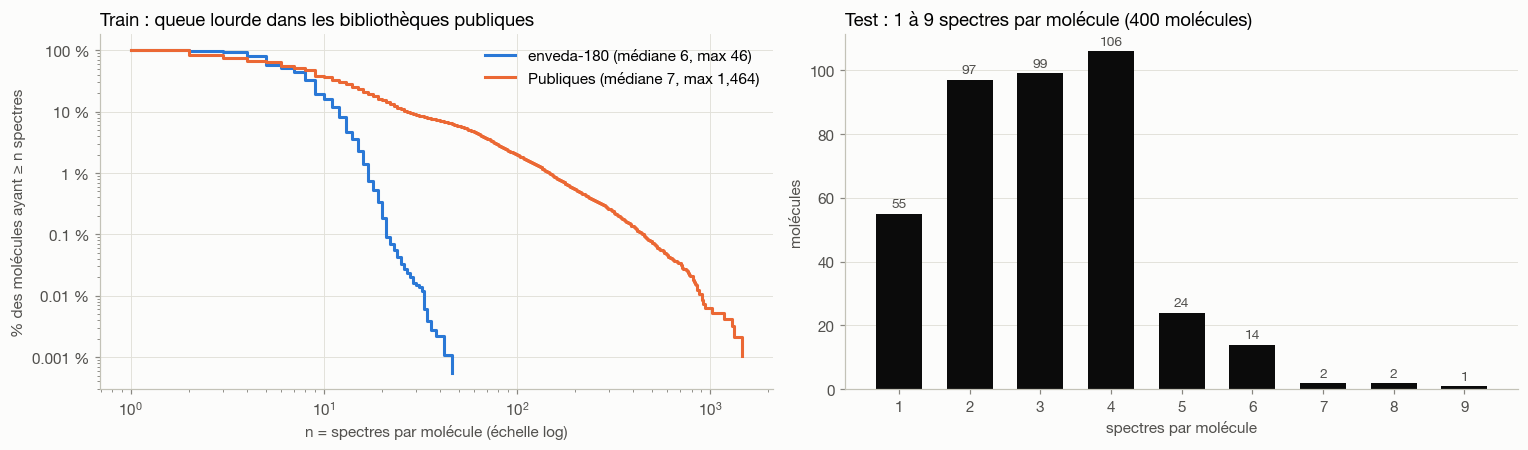

inchikey14,group,len,normalized_smiles
str,str,u32,str
"""LPLVUJXQOOQHMX""","""Publiques""",1329,"""CC1(C(=O)O)CCC2(C)CCC3(C)C(=CC(=O)C4C5(C)CCC(OC6OC(C(=O)O)C(…"
"""PFTAWBLQPZVEMU""","""Publiques""",1464,"""Oc1cc(O)c2c(c1)OC(c1ccc(O)c(O)c1)C(O)C2"""
"""RWXIFXNRCLMQCD""","""Publiques""",1171,"""CC(C)=CCCC(C)(O)C1CCC2(C)C1C(O)CC1C3(C)CCC(OC4OC(CO)C(O)C(O)…"
"""AIONOLUJZLIMTK""","""Publiques""",1301,"""COc1ccc(C2CC(=O)c3c(O)cc(O)cc3O2)cc1O"""
"""TZBJGXHYKVUXJN""","""Publiques""",1015,"""O=c1c(-c2ccc(O)cc2)coc2cc(O)cc(O)c12"""


In [15]:
spm_train = meta.group_by("inchikey14", "group").len()
spm_test  = test.group_by("molecule_id").len()

fig, (a0, a1) = plt.subplots(1, 2, figsize=(14, 4.2))
# Fonction de survie P(N >= n) : lisible sur données entières à queue lourde
for g in ["enveda-180", "Publiques"]:
    v = np.sort(spm_train.filter(pl.col("group") == g)["len"].to_numpy())
    n = np.unique(v); surv = 1 - np.searchsorted(v, n, side="left") / len(v)
    a0.step(n, surv * 100, where="post", color=COL[g], label=f"{g} (médiane {np.median(v):.0f}, max {v.max():,})")
a0.set_xscale("log"); a0.set_yscale("log"); a0.set_xlabel("n = spectres par molécule (échelle log)"); a0.set_ylabel("% des molécules ayant ≥ n spectres")
a0.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g} %"))
a0.set_title("Train : queue lourde dans les bibliothèques publiques"); a0.legend()

vc = spm_test["len"].value_counts().sort("len")
a1.bar(vc["len"], vc["count"], color=INK, width=0.65)
for x, y in zip(vc["len"], vc["count"]): a1.text(x, y + 2, str(y), ha="center", fontsize=9, color=INK2)
a1.set_xlabel("spectres par molécule"); a1.set_ylabel("molécules"); a1.set_title("Test : 1 à 9 spectres par molécule (400 molécules)")
a1.set_xticks(vc["len"]); a1.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

top = spm_train.sort("len", descending=True).head(5).join(meta.select("inchikey14", "normalized_smiles").unique("inchikey14"), on="inchikey14")
top

In [16]:
# Combinaisons de conditions par molécule de test (polarités et énergies disponibles)
cond = (test.with_columns((pl.col("ionization_mode").str.slice(0, 3) + ":" + pl.col("collision_energy_orig").str.replace_all("-", "")).alias("cond"))
            .group_by("molecule_id").agg(pl.col("ionization_mode").n_unique().alias("n_polarites"),
                                         pl.col("cond").unique().sort().str.join(" | ").alias("conditions")))
print(cond["n_polarites"].value_counts().sort("n_polarites"))
cond["conditions"].value_counts(sort=True).head(10)

shape: (2, 2)
┌─────────────┬───────┐
│ n_polarites ┆ count │
│ ---         ┆ ---   │
│ u32         ┆ u32   │
╞═════════════╪═══════╡
│ 1           ┆ 303   │
│ 2           ┆ 97    │
└─────────────┴───────┘


conditions,count
str,u32
"""pos:20 | pos:20,40,60 | pos:40 | pos:60""",81
"""pos:20,40,60 | pos:40 | pos:60""",57
"""pos:40 | pos:60""",23
"""pos:60""",22
"""pos:20,40,60 | pos:60""",16
"""pos:20,40,60 | pos:40""",14
"""pos:20 | pos:40 | pos:60""",12
"""pos:40""",12
"""pos:20,40,60""",11


**Ce qu'on retient**
- Train : médiane de 6 à 7 spectres par molécule. enveda-180 est borné (≤ ~50), mais les bibliothèques publiques ont une **queue très lourde** : quelques produits naturels standards (génistéine, catéchine, glycyrrhizine…) atteignent **plus de 1 000 spectres**. Sans précaution, l'entraînement serait dominé par ces molécules. Il faut **pondérer par 1/n_spectres** ou sous-échantillonner.
- Test : chaque molécule a typiquement 2 à 4 spectres (énergies 20/40/60 plus le spectre fusionné), et **97 molécules sur 400 ont les deux polarités**. Il faut une **stratégie d'agrégation multi-spectres** : fusion des pics, ou moyenne des scores des candidats.
- **Validation** : découpage obligatoirement **par `inchikey14`** (GroupKFold), sinon des spectres d'une même molécule se retrouvent dans le train et la validation.

## 5. Ion précurseur, adduits et masse neutre

`precursor_mz` est la masse/charge de l'ion intact. Avec l'**adduit**, on remonte à la **masse neutre exacte M** de la molécule, la contrainte la plus forte sur la structure. C'est la feature n° 1.

### 5.1 Les adduits

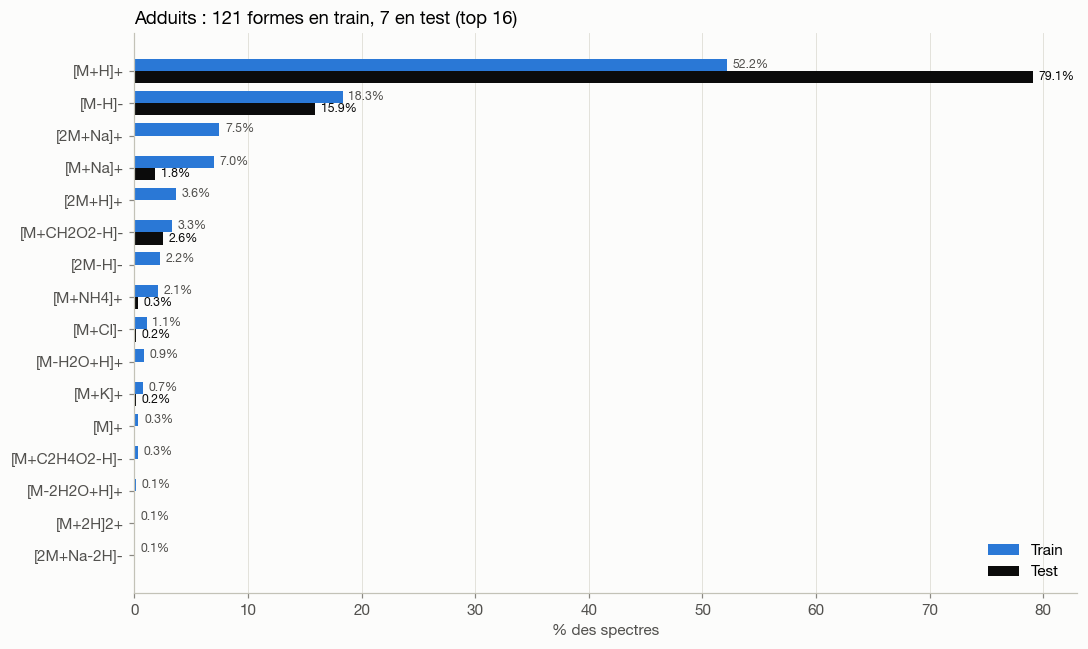

Spectres train dont l'adduit est absent du test : 15.3%


In [17]:
add_tr = meta["adduct"].value_counts().with_columns((pl.col("count") / pl.col("count").sum()).alias("p_train"))
add_te = test["adduct"].value_counts().with_columns((pl.col("count") / pl.col("count").sum()).alias("p_test"))
add = add_tr.join(add_te.select("adduct", "p_test"), on="adduct", how="full", coalesce=True).fill_null(0)
add = add.sort("p_train", descending=True).head(16).sort("p_train")

fig, ax = plt.subplots(figsize=(10, 6))
y = np.arange(len(add)); h = 0.38
ax.barh(y + h/2, add["p_train"] * 100, height=h, color=COL["enveda-180"], label="Train")
ax.barh(y - h/2, add["p_test"] * 100,  height=h, color=INK, label="Test")
ax.set_yticks(y, add["adduct"]); ax.set_xlabel("% des spectres"); ax.grid(axis="y", visible=False)
for yy, a, b in zip(y, add["p_train"], add["p_test"]):
    ax.text(a * 100 + 0.5, yy + h/2, f"{a:.1%}", va="center", fontsize=8, color=INK2)
    if b > 0: ax.text(b * 100 + 0.5, yy - h/2, f"{b:.1%}", va="center", fontsize=8, color=INK)
ax.set_title(f"Adduits : {meta['adduct'].n_unique()} formes en train, {test['adduct'].n_unique()} en test (top 16)")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

print("Spectres train dont l'adduit est absent du test :", f"{(~meta['adduct'].is_in(test['adduct'].unique())).mean():.1%}")

**Ce qu'on retient** : le test ne contient que **7 adduits** mono-chargés (79 % de `[M+H]+`). Environ 15 % du train utilise des adduits absents du test, surtout les **dimères `[2M+Na]+` et `[2M+H]+`** d'enveda-180. On peut les **exclure** ou les garder seulement pour du pré-entraînement. L'adduit est une feature catégorielle à encoder en one-hot (7 classes), car il change le mode de fragmentation : les adduits sodium fragmentent peu, le formiate perd souvent HCOOH.

### 5.2 Masse précurseur et masse neutre

Cohérence intra-molécule (test) : écart max de masse neutre = 1.85 mDa
precursor_mz < 50 : 52 | > 2000 : 25


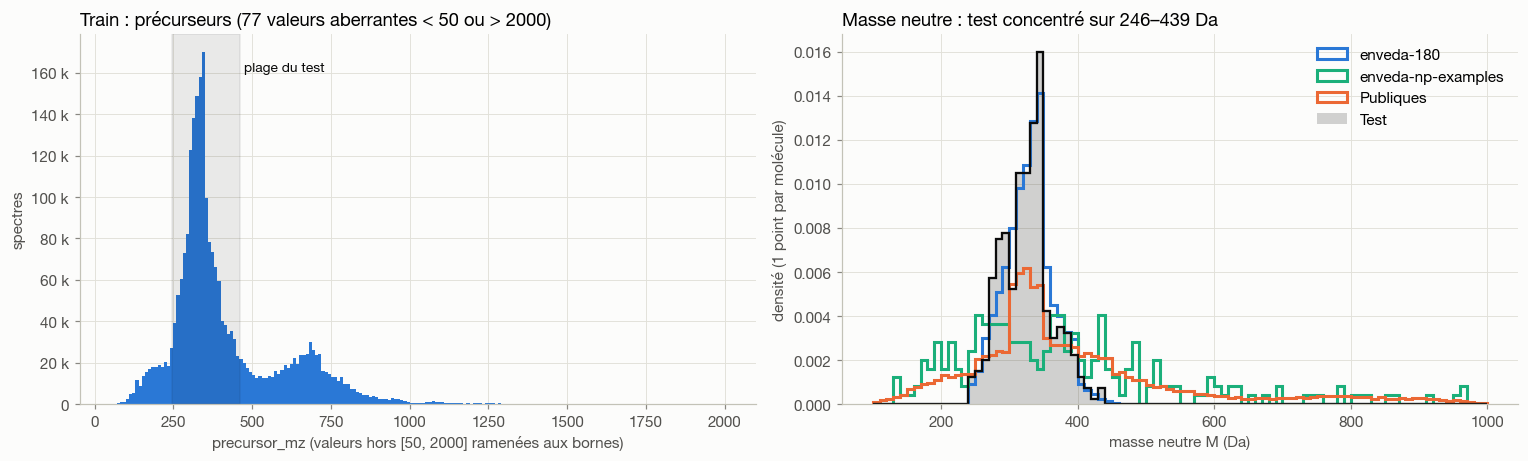

In [18]:
SHIFT = {"[M+H]+": 1.007276, "[M-H]-": -1.007276, "[M+Na]+": 22.989218, "[M+NH4]+": 18.033823,
         "[M+K]+": 38.963158, "[M+Cl]-": 34.969402, "[M+CH2O2-H]-": 44.998201}

def add_neutral_mass(df):
    return (df.filter(pl.col("adduct").is_in(list(SHIFT)))
              .with_columns((pl.col("precursor_mz") - pl.col("adduct").replace_strict(SHIFT)).alias("neutral_mass")))

meta7 = add_neutral_mass(meta); test7 = add_neutral_mass(test)
test_mol = test7.group_by("molecule_id").agg(pl.col("neutral_mass").mean(), (pl.col("neutral_mass").max() - pl.col("neutral_mass").min()).alias("spread"))
print(f"Cohérence intra-molécule (test) : écart max de masse neutre = {test_mol['spread'].max()*1000:.2f} mDa")

fig, (a0, a1) = plt.subplots(1, 2, figsize=(14, 4.3))
pm = meta["precursor_mz"].to_numpy()
n_out = int(((pm < 50) | (pm > 2000)).sum())
a0.hist(np.clip(pm, 50, 2000), bins=np.arange(50, 2001, 10), color=COL["enveda-180"])
a0.set_xlabel("precursor_mz (valeurs hors [50, 2000] ramenées aux bornes)"); a0.set_ylabel("spectres"); fmt_thousands(a0, "y")
a0.set_title(f"Train : précurseurs ({n_out} valeurs aberrantes < 50 ou > 2000)")
lo, hi = test["precursor_mz"].min(), test["precursor_mz"].max()
a0.axvspan(lo, hi, color=INK, alpha=0.08); a0.text(hi + 15, a0.get_ylim()[1] * 0.9, "plage du test", color=INK, fontsize=9)
print(f"precursor_mz < 50 : {(pm < 50).sum():,} | > 2000 : {(pm > 2000).sum():,}")

bins = np.arange(100, 1001, 10)
for g in ["enveda-180", "enveda-np-examples", "Publiques"]:
    v = meta7.filter(pl.col("group") == g).unique("inchikey14")["neutral_mass"].to_numpy()
    a1.hist(v, bins=bins, density=True, histtype="step", lw=2, color=COL[g], label=g)
a1.hist(test_mol["neutral_mass"].to_numpy(), bins=bins, density=True, color=INK, alpha=0.18, label="Test")
a1.hist(test_mol["neutral_mass"].to_numpy(), bins=bins, density=True, histtype="step", color=INK, lw=1.5)
a1.set_xlabel("masse neutre M (Da)"); a1.set_ylabel("densité (1 point par molécule)"); a1.legend()
a1.set_title(f"Masse neutre : test concentré sur {test_mol['neutral_mass'].min():.0f}–{test_mol['neutral_mass'].max():.0f} Da")
plt.tight_layout(); plt.show()

**Ce qu'on retient**
- La masse neutre calculée est **cohérente au milli-Dalton près** entre les spectres d'une même molécule de test. Les adduits sont donc fiables, et la masse neutre est une feature robuste au niveau molécule.
- Le second mode du précurseur vers ~650–700 correspond aux **dimères `[2M+Na]+` / `[2M+H]+`** d'enveda-180.
- Le test couvre une **fenêtre étroite (~245–440 Da)**, alors que le train s'étend de 100 à plus de 1 000 Da. Pour la validation ou l'entraînement ciblé, on peut **restreindre le train à ~200–500 Da**.

### 5.3 Erreur de masse (qualité de l'annotation)

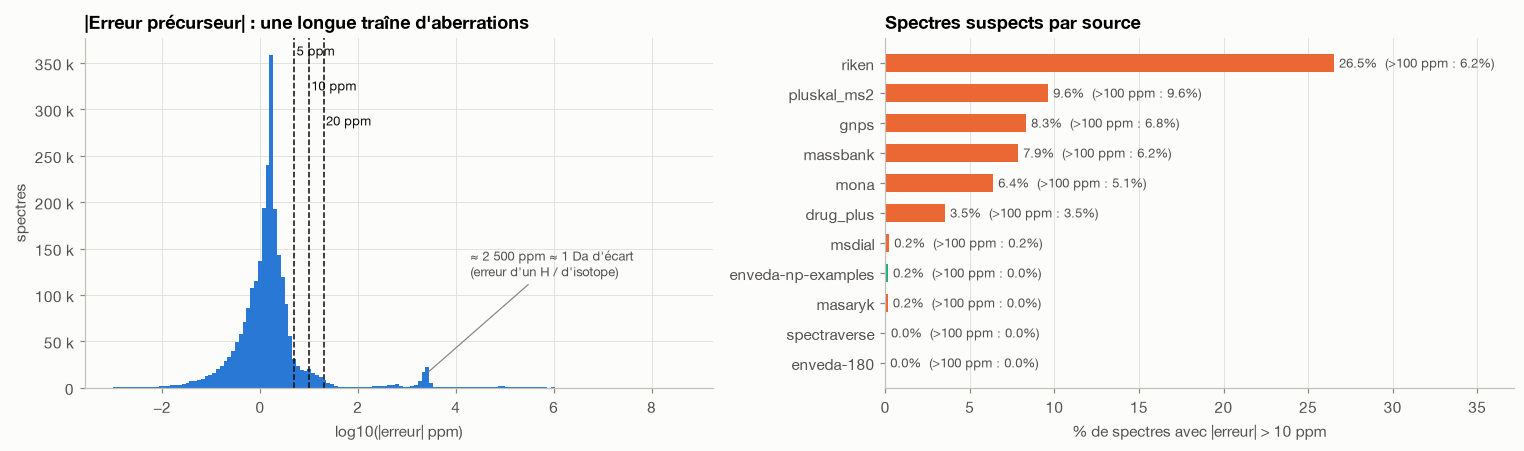

Quantiles |ppm| : {'q50': 1.51, 'q90': 5.04, 'q95': 17.18, 'q99': 2884.42}


In [17]:
ppm = meta.filter(pl.col("precursor_error_ppm").is_not_null()).with_columns(pl.col("precursor_error_ppm").abs().alias("abs_ppm"))
fig, (a0, a1) = plt.subplots(1, 2, figsize=(14, 4.2))
a0.hist(np.log10(ppm["abs_ppm"].to_numpy() + 1e-3), bins=150, color=COL["enveda-180"])
for thr, yf in [(5, 0.95), (10, 0.85), (20, 0.75)]:
    a0.axvline(np.log10(thr), color=INK, lw=1, ls="--"); a0.text(np.log10(thr) + 0.05, a0.get_ylim()[1] * yf, f"{thr} ppm", fontsize=8.5, color=INK)
a0.annotate("≈ 2 500 ppm ≈ 1 Da d'écart\n(erreur d'un H / d'isotope)", (3.4, 15000), (4.3, 120000), fontsize=8.5, color=INK2,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
a0.set_xlabel("log10(|erreur| ppm)"); a0.set_ylabel("spectres"); fmt_thousands(a0, "y"); a0.set_title("|Erreur précurseur| : une longue traîne d'aberrations")

q = ppm.group_by("ingest_lib").agg((pl.col("abs_ppm") > 10).mean().alias("p10"), (pl.col("abs_ppm") > 100).mean().alias("p100"), lib_group().first()).sort("p10")
a1.barh(q["ingest_lib"], q["p10"] * 100, color=[COL[g] for g in q["group"]], height=0.6)
for y, v, v2 in zip(range(len(q)), q["p10"], q["p100"]):
    a1.text(v * 100 + 0.3, y, f"{v:.1%}  (>100 ppm : {v2:.1%})", va="center", fontsize=8.5, color=INK2)
a1.set_xlabel("% de spectres avec |erreur| > 10 ppm"); a1.set_xlim(0, q["p10"].max() * 140); a1.grid(axis="y", visible=False)
a1.set_title("Spectres suspects par source")
plt.tight_layout(); plt.show()
print("Quantiles |ppm| :", {f"q{int(p*100)}": round(ppm["abs_ppm"].quantile(p), 2) for p in [.5, .9, .95, .99]})

**Ce qu'on retient** : la médiane est autour de 1,5 ppm (très bonne précision), mais ~7 % des spectres dépassent 10 ppm. Ce n'est pas uniforme : **riken (26 %)**, pluskal et gnps concentrent les problèmes, alors qu'enveda-180 est propre. Chez riken, l'essentiel se situe entre 10 et 100 ppm. Ces spectres ont presque tous un `precursor_mz` saisi avec ≤ 3 décimales (98 %, contre 70 % pour le reste de riken) : c'est une **faible précision de mesure ou de saisie** plutôt qu'une erreur de structure. Ils sont donc moins graves que les erreurs > 100 ppm. Le petit mode vers 10^3,4 ppm correspond à un **écart d'environ 1 Da** : un hydrogène de trop ou de moins, ou l'isotope M+1 annoté comme précurseur. Ce sont des **erreurs d'annotation**, pas du bruit de mesure. Filtre recommandé : **|ppm| ≤ 20**. Ce champ n'existe pas en test ; c'est un outil de **nettoyage**, pas une feature.

## 6. Énergie de collision et instruments

L'énergie de collision (CE) contrôle **le degré de fragmentation** : à basse énergie, le précurseur reste majoritaire ; à haute énergie, on observe de petits fragments. Elle est déclarée dans 4 unités différentes.

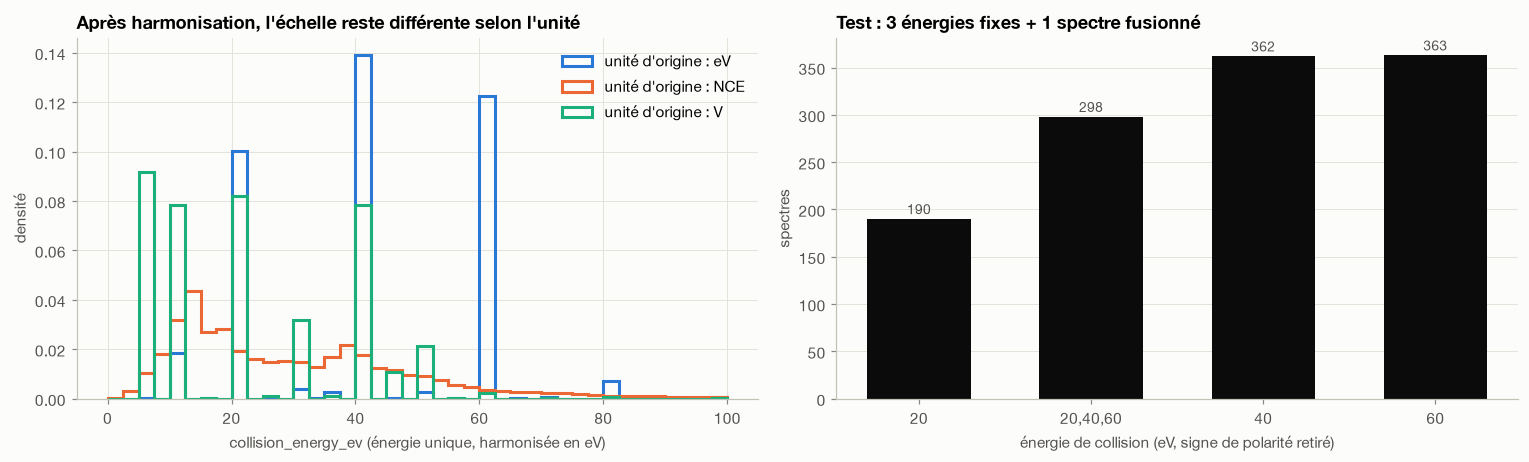

Part du train sans CE exploitable : 13.3%


In [18]:
ce = meta.select("ingest_lib", "group", "collision_energy_orig_units", "collision_energy_ev").with_columns(
        pl.col("collision_energy_ev").list.len().fill_null(0).alias("n_ce"),
        pl.col("collision_energy_ev").list.mean().alias("ce_mean"))

fig, (a0, a1) = plt.subplots(1, 2, figsize=(14, 4.3))
bins = np.arange(0, 101, 2.5)
for u, c in zip(["eV", "NCE", "V"], [COL["enveda-180"], COL["Publiques"], COL["enveda-np-examples"]]):
    v = ce.filter((pl.col("collision_energy_orig_units") == u) & (pl.col("n_ce") == 1))["ce_mean"].drop_nulls().to_numpy()
    a0.hist(v, bins=bins, density=True, histtype="step", lw=2, color=c, label=f"unité d'origine : {u}")
a0.set_xlabel("collision_energy_ev (énergie unique, harmonisée en eV)"); a0.set_ylabel("densité"); a0.legend()
a0.set_title("Après harmonisation, l'échelle reste différente selon l'unité")

tc = test["collision_energy_orig"].str.replace_all("-", "").str.replace("60,40,20", "20,40,60").value_counts().sort("collision_energy_orig")
a1.bar(tc["collision_energy_orig"], tc["count"], color=INK, width=0.6)
for x, y in enumerate(tc["count"]): a1.text(x, y + 5, str(y), ha="center", fontsize=9, color=INK2)
a1.set_xlabel("énergie de collision (eV, signe de polarité retiré)"); a1.set_ylabel("spectres"); a1.grid(axis="x", visible=False)
a1.set_title("Test : 3 énergies fixes + 1 spectre fusionné")
plt.tight_layout(); plt.show()

print("Part du train sans CE exploitable :", f"{(ce['n_ce'] == 0).mean():.1%}")

83 libellés bruts -> 7 familles


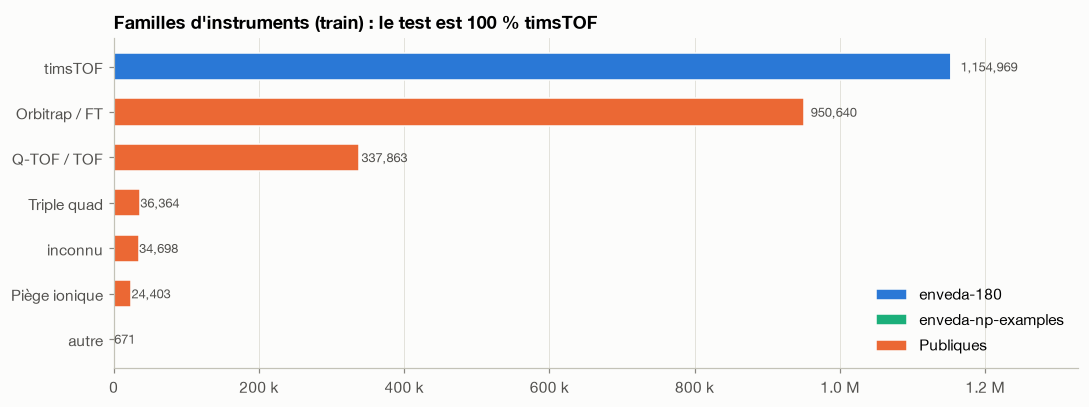

In [19]:
# Harmonisation de instrument_type : 83 libellés -> 7 familles (dont "inconnu" et "autre")
def instrument_group(col="instrument_type"):
    s = pl.col(col).str.to_lowercase().fill_null("")
    return (pl.when(s.is_in(["", "nan", "n/a"])).then(pl.lit("inconnu"))
              .when(s.str.contains("tims")).then(pl.lit("timsTOF"))
              .when(s.str.contains(r"orbitrap|qft|itft|exactive|qehf|hybrid ft|-ft|^ft|hcd|qit-ft")).then(pl.lit("Orbitrap / FT"))
              .when(s.str.contains(r"tof")).then(pl.lit("Q-TOF / TOF"))
              .when(s.str.contains(r"qqq|qq|quattro|^q$|-q$")).then(pl.lit("Triple quad"))
              .when(s.str.contains(r"trap|qit|lit|-it$")).then(pl.lit("Piège ionique"))
              .otherwise(pl.lit("autre")).alias("instrument_group"))

meta = meta.with_columns(instrument_group())
print(f"{meta['instrument_type'].n_unique()} libellés bruts -> {meta['instrument_group'].n_unique()} familles")
ig = meta.group_by("instrument_group", "group").len().pivot(on="group", index="instrument_group", values="len").fill_null(0)
ig = ig.with_columns(pl.sum_horizontal(pl.exclude("instrument_group")).alias("tot")).sort("tot")

fig, ax = plt.subplots(figsize=(10, 3.8))
left = np.zeros(len(ig))
for g in ["enveda-180", "enveda-np-examples", "Publiques"]:
    v = ig[g].to_numpy() if g in ig.columns else np.zeros(len(ig))
    ax.barh(ig["instrument_group"], v, left=left, color=COL[g], height=0.6, label=g, edgecolor=SURF, linewidth=1)
    left += v
for y, v in enumerate(left): ax.text(v * 1.01, y, f"{v:,.0f}", va="center", fontsize=8.5, color=INK2)
fmt_thousands(ax); ax.set_xlim(0, left.max() * 1.15); ax.grid(axis="y", visible=False); ax.legend(loc="lower right")
ax.set_title("Familles d'instruments (train) : le test est 100 % timsTOF")
plt.tight_layout(); plt.show()

**Ce qu'on retient**
- Le test utilise **exactement** les énergies 20, 40 et 60 eV, plus un spectre « fusionné » `20,40,60`. Dans le train, seul enveda-180 reproduit ce protocole. Les énergies NCE (Orbitrap) converties en eV ne sont **pas strictement comparables** à des eV timsTOF.
- Features : `ce_min`, `ce_max`, `ce_is_merged` (liste de plusieurs valeurs), `ce_missing`, et `instrument_group` en 7 classes.
- Le timsTOF du test ne représente que 45 % du train (enveda-180). Un modèle entraîné sans contrôle de l'instrument apprendrait en partie la signature Orbitrap.

## 7. Anatomie des spectres MS2

Un spectre est une liste de pics (m/z, intensité relative au pic de base = 1). On commence par **regarder des spectres**, puis on étudie leurs distributions.

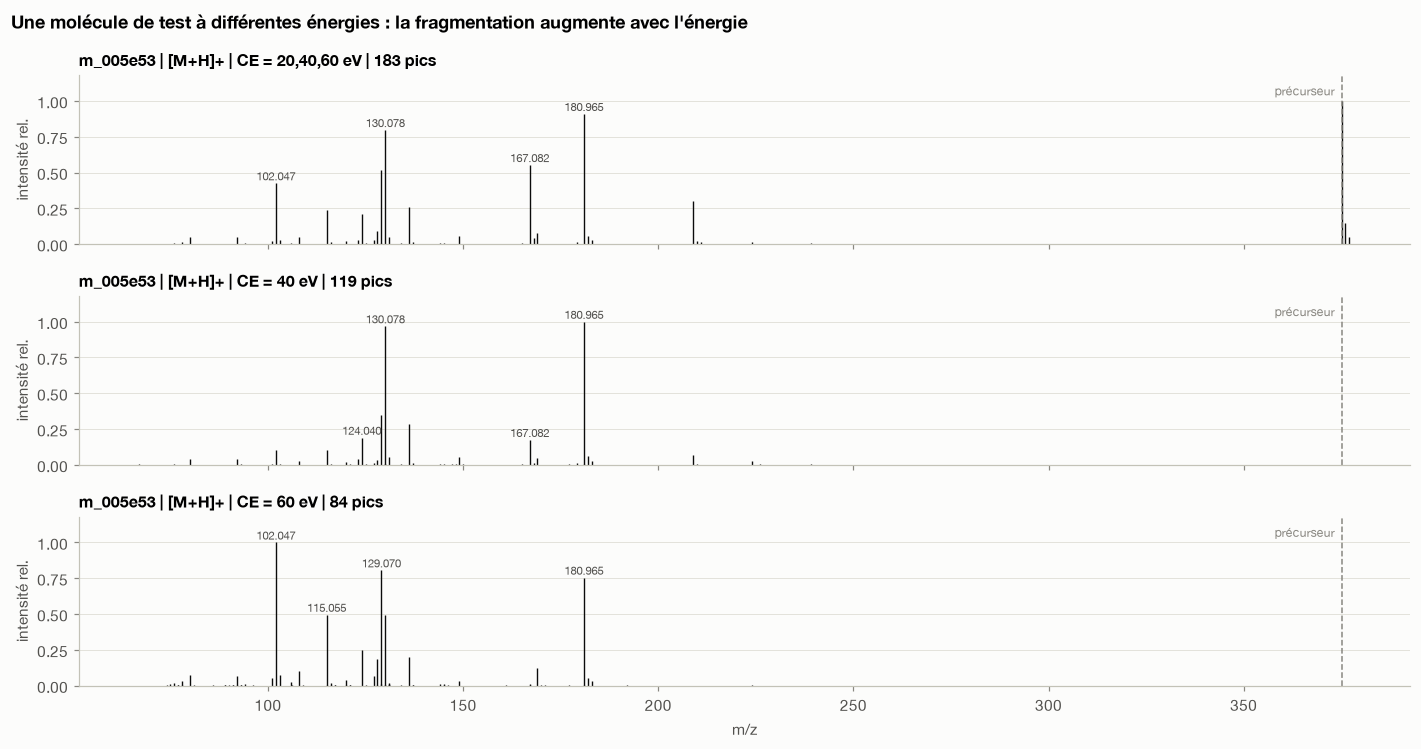

In [20]:
def stem(ax, mz, I, color, prec=None, title=None, label_top=4):
    mz, I = np.asarray(mz), np.asarray(I)
    ax.vlines(mz, 0, I, color=color, lw=0.9)
    if prec is not None:
        ax.axvline(prec, color=MUTED, lw=1, ls="--"); ax.text(prec - 1, 1.12, "précurseur ", fontsize=8, color=MUTED, ha="right", va="top")
    placed = []   # on n'étiquette que des pics bien séparés, pour éviter les chevauchements
    for k in np.argsort(I)[::-1]:
        if len(placed) == label_top: break
        if all(abs(mz[k] - p) > 6 for p in placed) and (prec is None or abs(mz[k] - prec) > 6):
            ax.text(mz[k], I[k] + 0.02, f"{mz[k]:.3f}", fontsize=7.5, ha="center", color=INK2); placed.append(mz[k])
    ax.set_ylim(0, 1.18); ax.set_ylabel("intensité rel."); ax.grid(axis="x", visible=False)
    if title: ax.set_title(title, fontsize=10.5)

mol = test.filter((pl.col("molecule_id") == ex_id) & (pl.col("ionization_mode") == "positive")).sort("collision_energy_orig")
fig, axes = plt.subplots(len(mol), 1, figsize=(13, 2.3 * len(mol)), sharex=True)
for ax, r in zip(np.atleast_1d(axes), mol.iter_rows(named=True)):
    stem(ax, r["ms2_mzs"], r["ms2_normalized_intensities"], INK, r["precursor_mz"],
         f"{r['molecule_id']} | {r['adduct']} | CE = {r['collision_energy_orig']} eV | {len(r['ms2_mzs'])} pics")
np.atleast_1d(axes)[-1].set_xlabel("m/z")
fig.suptitle("Une molécule de test à différentes énergies : la fragmentation augmente avec l'énergie", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

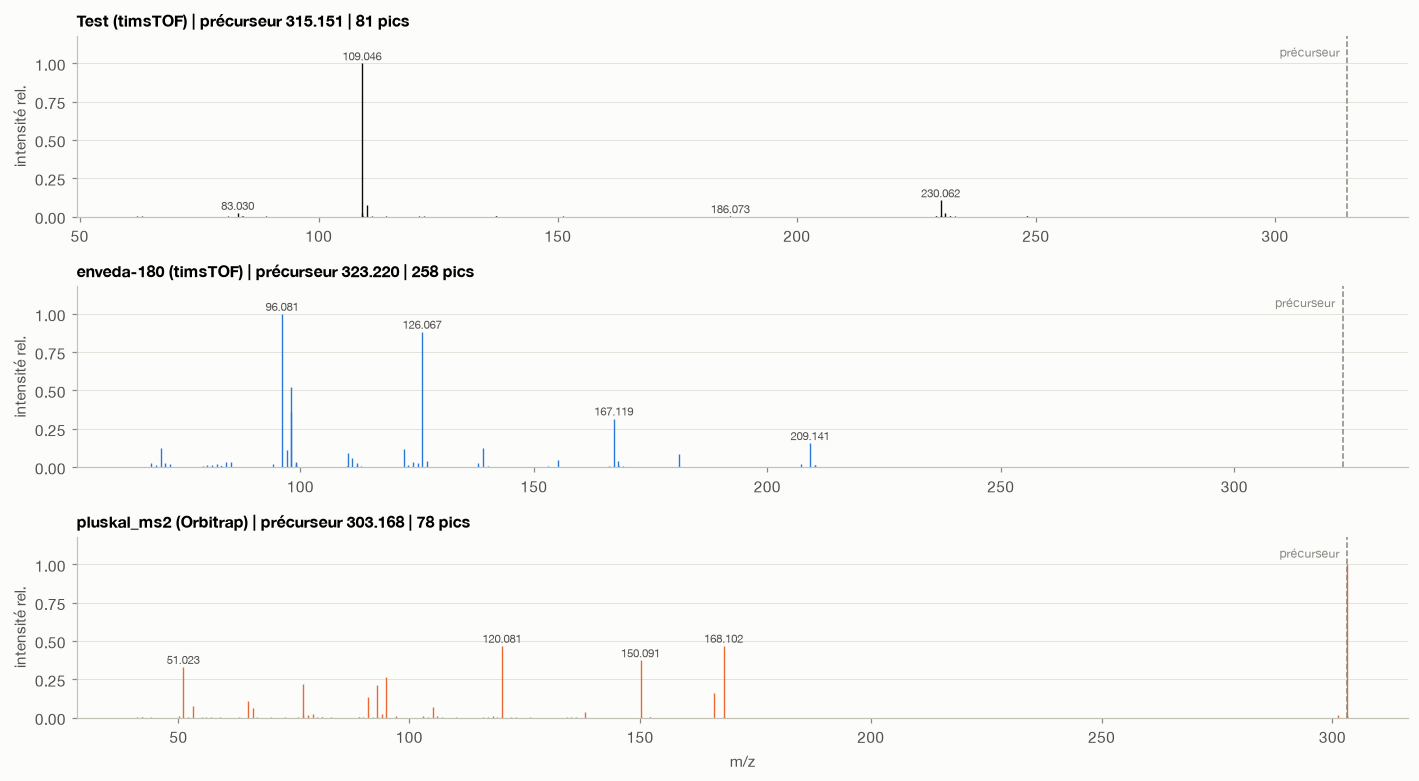

In [21]:
# Même échelle, trois origines : test, enveda-180 (timsTOF), une bibliothèque publique Orbitrap
rng = np.random.default_rng(SEED)
pick = lambda df: df.row(int(rng.integers(len(df))), named=True)
cands = {
    "Test (timsTOF)":            (test.filter((pl.col("adduct") == "[M+H]+") & (pl.col("collision_energy_orig") == "40")), INK),
    "enveda-180 (timsTOF)":      (spec.filter((pl.col("ingest_lib") == "enveda-180") & (pl.col("adduct") == "[M+H]+") & (pl.col("collision_energy_orig") == "40")), COL["enveda-180"]),
    "pluskal_ms2 (Orbitrap)":    (spec.filter((pl.col("ingest_lib") == "pluskal_ms2") & (pl.col("adduct") == "[M+H]+") & pl.col("precursor_mz").is_between(300, 360)), COL["Publiques"]),
}
fig, axes = plt.subplots(3, 1, figsize=(13, 7.2))
for ax, (name, (df, c)) in zip(axes, cands.items()):
    r = pick(df.filter(pl.col("precursor_mz").is_between(300, 360)))
    stem(ax, r["ms2_mzs"], r["ms2_normalized_intensities"], c, r["precursor_mz"], f"{name} | précurseur {r['precursor_mz']:.3f} | {len(r['ms2_mzs'])} pics")
axes[-1].set_xlabel("m/z")
plt.tight_layout(); plt.show()

Les spectres timsTOF (test, enveda-180) contiennent **une forêt de petits pics**, alors que les spectres Orbitrap publics sont souvent déjà « centroïdés et filtrés » (quelques dizaines de pics). Quantifions-le.

In [22]:
def spec_stats(df):
    rows = []
    for g, lib, mz, I, p in df.select("group", "ingest_lib", "ms2_mzs", "ms2_normalized_intensities", "precursor_mz").iter_rows():
        mz, I = np.asarray(mz), np.asarray(I)
        below = mz <= p + 0.5
        Ib = I[below]; pb = Ib / Ib.sum() if Ib.sum() > 0 else Ib
        near = np.abs(mz - p) <= max(0.01, p * 10e-6)
        rows.append((g, lib, len(mz), int((I >= 0.01).sum()), float(-(pb * np.log(pb + 1e-12)).sum()),
                     float(I[near].sum() / I.sum()) if I.sum() > 0 else np.nan, int((~below).sum()), float(np.median(I))))
    return pl.DataFrame(rows, schema=["group", "ingest_lib", "n_peaks", "n_peaks_1pct", "entropy", "prec_frac", "n_above_prec", "median_int"], orient="row")

f_ss = CACHE / "spec_stats.parquet"
if not f_ss.exists():
    spec_stats(pl.concat([spec.select(test.select("group", "ingest_lib", "ms2_mzs", "ms2_normalized_intensities", "precursor_mz").columns),
                          test.select("group", "ingest_lib", "ms2_mzs", "ms2_normalized_intensities", "precursor_mz")])).write_parquet(f_ss)
ss = pl.read_parquet(f_ss)
ss.group_by("group").agg(pl.len(), *[pl.col(c).median() for c in ["n_peaks", "n_peaks_1pct", "entropy", "prec_frac", "n_above_prec", "median_int"]])

group,len,n_peaks,n_peaks_1pct,entropy,prec_frac,n_above_prec,median_int
str,u32,f64,f64,f64,f64,f64,f64
"""Publiques""",41507,20.0,12.0,1.737254,0.0,0.0,0.02579
"""Test""",1213,230.0,18.0,2.26305,0.001139,1.0,0.000399
"""enveda-180""",34642,138.0,14.0,1.962165,0.0,0.0,0.000764
"""enveda-np-examples""",1184,141.5,28.0,2.764586,0.001744,0.5,0.003502


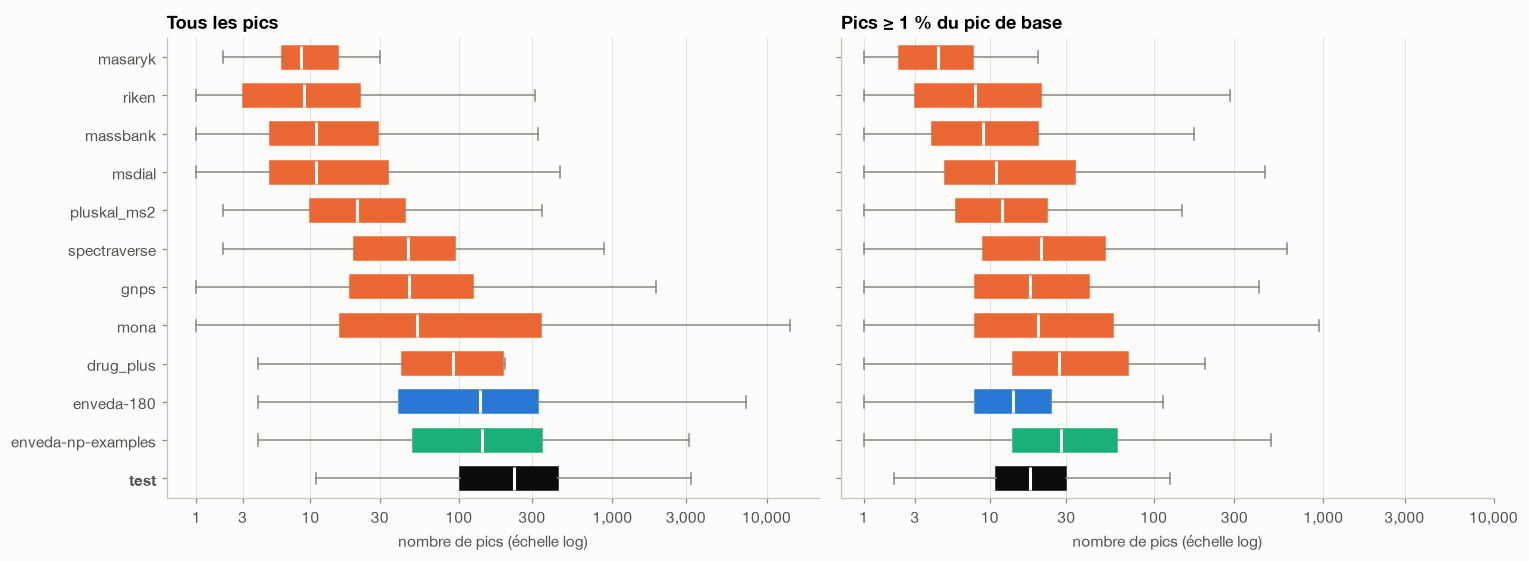

In [23]:
order_libs = (ss.filter(pl.col("group") != "Test").group_by("ingest_lib", "group").agg(pl.col("n_peaks").median().alias("m"))
                .sort("m", descending=True))
labels = ["test"] + order_libs["ingest_lib"].to_list()
colors = [INK] + [COL[g] for g in order_libs["group"]]

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), sharey=True)
for ax, c, t in zip(axes, ["n_peaks", "n_peaks_1pct"], ["Tous les pics", "Pics ≥ 1 % du pic de base"]):
    data = [np.log10(ss.filter(pl.col("ingest_lib") == l)[c].to_numpy() + 1) for l in labels]
    bp = ax.boxplot(data, vert=False, widths=0.6, patch_artist=True, showfliers=False, medianprops=dict(color=SURF, lw=2))
    for b, col in zip(bp["boxes"], colors): b.set(facecolor=col, edgecolor=col)
    for w in bp["whiskers"] + bp["caps"]: w.set(color=MUTED)
    ax.set_yticks(range(1, len(labels) + 1), labels); ax.invert_yaxis()
    ticks = [1, 3, 10, 30, 100, 300, 1000, 3000, 10000]
    ax.set_xticks(np.log10(np.array(ticks) + 1), [f"{t:,}" for t in ticks])
    ax.set_xlabel("nombre de pics (échelle log)"); ax.set_title(t); ax.grid(axis="y", visible=False)
axes[0].get_yticklabels()[0].set_fontweight("bold")
plt.tight_layout(); plt.show()

**Ce qu'on retient** : le test a **~230 pics en médiane**, 1,7 fois plus qu'enveda-180 (138) et 10 à 25 fois plus que riken ou massbank. Avec un seuil à 1 % du pic de base, les écarts se resserrent fortement. **La différence vient surtout de pics de bruit de très faible intensité.** Un **débruitage** (seuil relatif, top-k pics) est donc indispensable pour comparer les spectres de test au train.

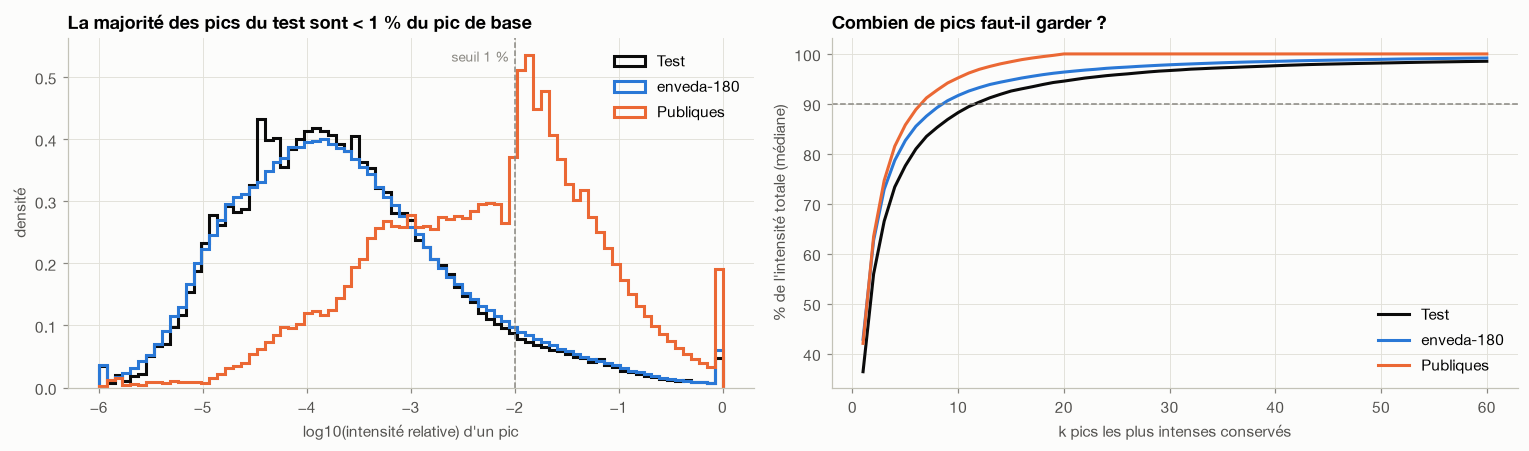

In [24]:
def flat(df, c): return df.select(pl.col(c).explode())[:, 0].to_numpy()
fig, (a0, a1) = plt.subplots(1, 2, figsize=(14, 4.2))
bins = np.linspace(-6, 0, 80)
for g, df in [("Test", test), ("enveda-180", spec.filter(pl.col("group") == "enveda-180")), ("Publiques", spec.filter(pl.col("group") == "Publiques"))]:
    v = np.log10(np.clip(flat(df, "ms2_normalized_intensities"), 1e-6, 1))
    a0.hist(v, bins=bins, density=True, histtype="step", lw=2, color=COL[g], label=g)
a0.axvline(-2, color=MUTED, ls="--", lw=1); a0.text(-2.05, a0.get_ylim()[1] * 0.97, "seuil 1 %", color=MUTED, fontsize=9, ha="right", va="top")
a0.set_xlabel("log10(intensité relative) d'un pic"); a0.set_ylabel("densité"); a0.legend(); a0.set_title("La majorité des pics du test sont < 1 % du pic de base")

# Fraction cumulée de l'intensité totale portée par les k pics les plus forts (test)
def topk_curve(df, K=60):
    out = []
    for I in df["ms2_normalized_intensities"]:
        s = np.sort(np.asarray(I))[::-1]; c = np.cumsum(s) / s.sum()
        out.append(np.pad(c[:K], (0, max(0, K - len(c))), constant_values=1.0))
    return np.median(np.vstack(out), axis=0)
for g, df in [("Test", test), ("enveda-180", spec.filter(pl.col("group") == "enveda-180").sample(5000, seed=SEED)), ("Publiques", spec.filter(pl.col("group") == "Publiques").sample(5000, seed=SEED))]:
    a1.plot(np.arange(1, 61), topk_curve(df) * 100, color=COL[g], label=g)
a1.axhline(90, color=MUTED, ls="--", lw=1)
a1.set_xlabel("k pics les plus intenses conservés"); a1.set_ylabel("% de l'intensité totale (médiane)"); a1.legend()
a1.set_title("Combien de pics faut-il garder ?")
plt.tight_layout(); plt.show()

**Ce qu'on retient**
- La distribution des intensités du test est **quasiment superposée à celle d'enveda-180** (même instrument, même traitement). Les bibliothèques publiques ont été filtrées en amont : elles n'ont presque aucun pic sous 0,1 %.
- Dans le test, **~12 pics** portent 90 % de l'intensité totale (médiane), et une trentaine en portent ~97 %. Un prétraitement **top-k (k ≈ 50)** et un **seuil relatif (≥ 0,5–1 %)** conservent l'information en supprimant le bruit. Les intensités s'étalent sur 6 ordres de grandeur : il faut utiliser une **transformation √ ou log** pour qu'un seul pic ne domine pas les similarités ou les embeddings.

### Pics au-delà du précurseur : l'enveloppe isotopique

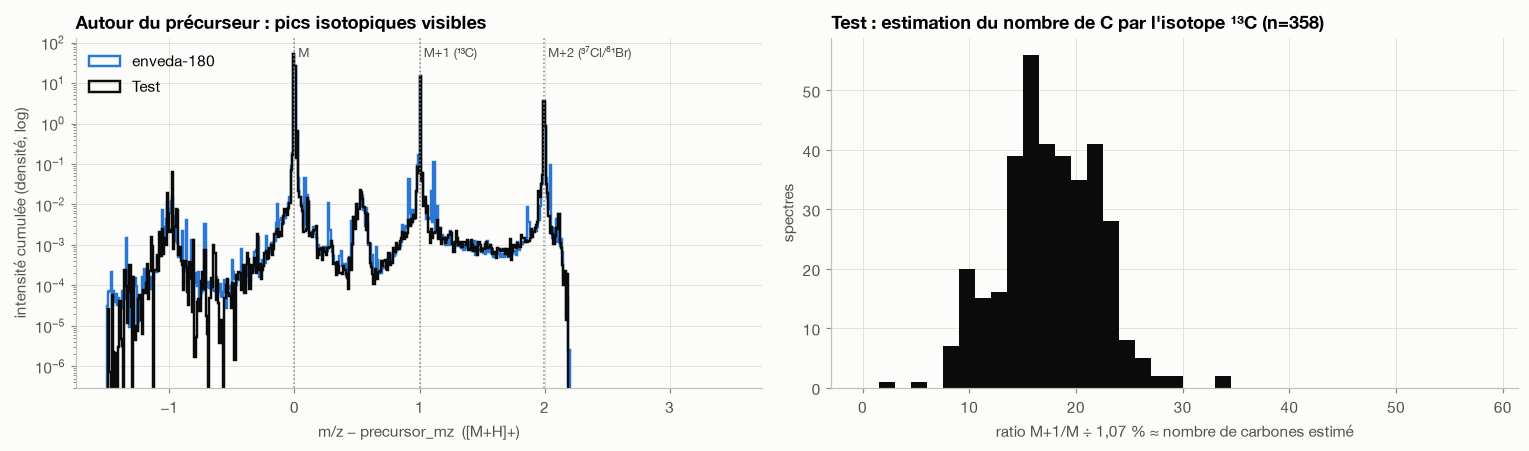

In [25]:
fig, (a0, a1) = plt.subplots(1, 2, figsize=(14, 4.2))
d = []
for df, g in [(test, "Test"), (spec.filter(pl.col("group") == "enveda-180").sample(8000, seed=SEED), "enveda-180")]:
    for mz, I, p in df.filter(pl.col("adduct") == "[M+H]+").select("ms2_mzs", "ms2_normalized_intensities", "precursor_mz").iter_rows():
        mz, I = np.asarray(mz), np.asarray(I); k = (mz > p - 1.5) & (mz < p + 3.5)
        d += [(g, x - p, w) for x, w in zip(mz[k], I[k])]
d = pl.DataFrame(d, schema=["group", "delta", "I"], orient="row")
for g in ["enveda-180", "Test"]:
    v = d.filter(pl.col("group") == g)
    a0.hist(v["delta"], bins=np.arange(-1.5, 3.5, 0.01), weights=v["I"], density=True, histtype="step", lw=1.6, color=COL[g], label=g)
for x, lab in [(0, "M"), (1.00336, "M+1 (¹³C)"), (1.99705, "M+2 (³⁷Cl/⁸¹Br)")]:
    a0.axvline(x, color=MUTED, ls=":", lw=1); a0.text(x + 0.03, a0.get_ylim()[1] * 0.8, lab, fontsize=8.5, color=INK2)
a0.set_yscale("log"); a0.set_xlabel("m/z − precursor_mz  ([M+H]+)"); a0.set_ylabel("intensité cumulée (densité, log)")
a0.set_title("Autour du précurseur : pics isotopiques visibles"); a0.legend()

r13 = []
for mz, I, p in test.filter(pl.col("adduct") == "[M+H]+").select("ms2_mzs", "ms2_normalized_intensities", "precursor_mz").iter_rows():
    mz, I = np.asarray(mz), np.asarray(I)
    f = lambda x: I[np.abs(mz - x) < 0.005].max() if (np.abs(mz - x) < 0.005).any() else 0
    a, b = f(p), f(p + 1.00336)
    if a > 0.05 and b > 0: r13.append(b / a / 0.0107)
a1.hist(r13, bins=np.arange(0, 60, 1.5), color=INK)
a1.set_xlabel("ratio M+1/M ÷ 1,07 % ≈ nombre de carbones estimé"); a1.set_ylabel("spectres")
a1.set_title(f"Test : estimation du nombre de C par l'isotope ¹³C (n={len(r13)})")
plt.tight_layout(); plt.show()

**Ce qu'on retient** : la fenêtre d'isolement du précurseur sur le timsTOF s'étend jusqu'à environ **+2,2 Da** (coupure nette à droite). Elle laisse passer les **pics isotopiques M+1 et M+2**, avec un comportement identique pour enveda-180 et le test. Le ratio de M+1 par rapport à M donne une **estimation grossière du nombre de carbones**, centrée sur ~15–25 C, ce qui est cohérent avec des molécules de 250 à 450 Da. Cette estimation est bruitée, car l'isolement coupe partiellement l'enveloppe, mais elle peut aider à **filtrer des formules candidates**. Il faut **séparer ces pics** (features isotopiques) des pics de fragments (similarité).

## 8. Features spectrales dérivées

### 8.1 Entropie et intensité résiduelle du précurseur selon l'énergie

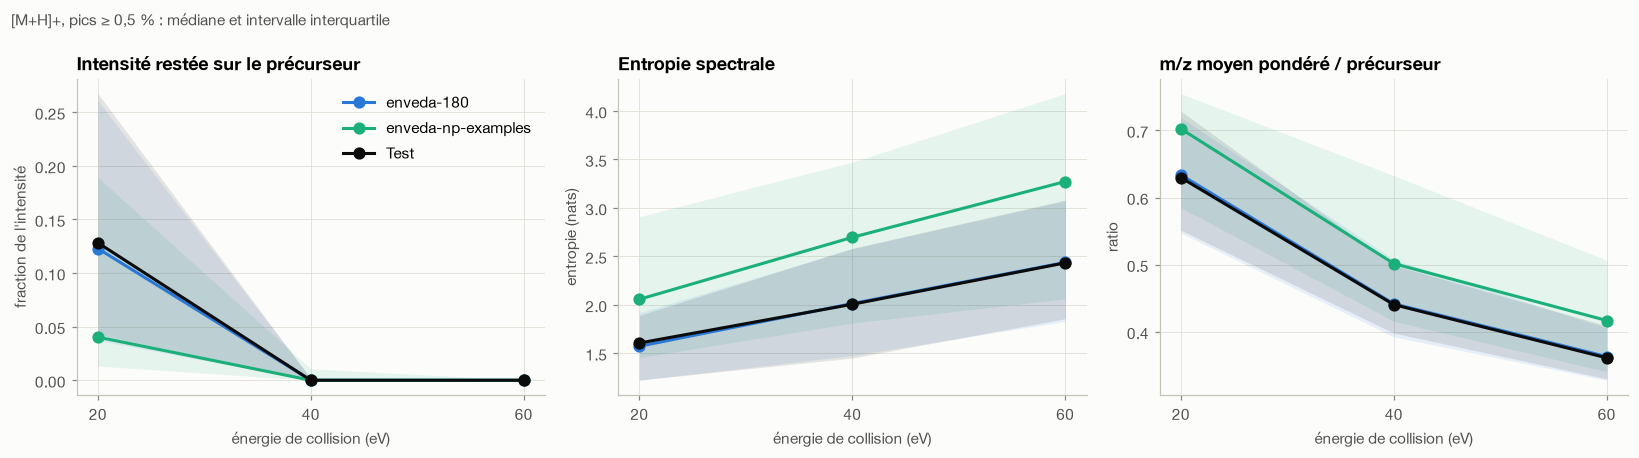

In [26]:
def ce_stats(df, g):
    rows = []
    for mz, I, p, ce in df.select("ms2_mzs", "ms2_normalized_intensities", "precursor_mz", "collision_energy_ev").iter_rows():
        if ce is None or len(ce) != 1: continue
        mz, I = np.asarray(mz), np.asarray(I); k = (mz <= p + 0.5) & (I >= 0.005)
        if k.sum() == 0: continue
        Ib = I[k] / I[k].sum()
        near = np.abs(mz[k] - p) <= max(0.01, p * 10e-6)
        rows.append((g, ce[0], float(-(Ib * np.log(Ib)).sum()), float(Ib[near].sum()), float((mz[k] * Ib).sum() / p)))
    return pl.DataFrame(rows, schema=["group", "ce", "entropy", "prec_frac", "rel_mz"], orient="row")

e180 = spec.filter((pl.col("group") == "enveda-180") & (pl.col("adduct") == "[M+H]+"))
npx  = spec.filter((pl.col("group") == "enveda-np-examples") & (pl.col("adduct") == "[M+H]+"))
cs = pl.concat([ce_stats(test.filter(pl.col("adduct") == "[M+H]+"), "Test"), ce_stats(e180, "enveda-180"), ce_stats(npx, "enveda-np-examples")])
agg = cs.filter(pl.col("ce").is_in([20.0, 40.0, 60.0])).group_by("group", "ce").agg(
          *[pl.col(c).median().alias(c) for c in ["entropy", "prec_frac", "rel_mz"]],
          *[pl.col(c).quantile(0.25).alias(c + "_q1") for c in ["entropy", "prec_frac", "rel_mz"]],
          *[pl.col(c).quantile(0.75).alias(c + "_q3") for c in ["entropy", "prec_frac", "rel_mz"]]).sort("ce")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, c, t, yl in zip(axes, ["prec_frac", "entropy", "rel_mz"],
                        ["Intensité restée sur le précurseur", "Entropie spectrale", "m/z moyen pondéré / précurseur"],
                        ["fraction de l'intensité", "entropie (nats)", "ratio"]):
    for g in ["enveda-180", "enveda-np-examples", "Test"]:
        a = agg.filter(pl.col("group") == g)
        ax.plot(a["ce"], a[c], marker="o", ms=7, color=COL[g], label=g)
        ax.fill_between(a["ce"], a[c + "_q1"], a[c + "_q3"], color=COL[g], alpha=0.10, lw=0)
    ax.set_xticks([20, 40, 60]); ax.set_xlabel("énergie de collision (eV)"); ax.set_ylabel(yl); ax.set_title(t)
axes[0].legend()
fig.suptitle("[M+H]+, pics ≥ 0,5 % : médiane et intervalle interquartile", x=0.01, ha="left", fontsize=10, color=INK2)
plt.tight_layout(); plt.show()

**Ce qu'on retient**
- L'énergie a un effet **massif et monotone** : à 20 eV, ~13 % de l'intensité reste en médiane sur le précurseur ; dès 40 eV, il est détruit. Les fragments deviennent plus petits (le m/z moyen pondéré passe de ~0,63 à ~0,36 × précurseur) et plus nombreux (l'entropie augmente).
- **Résultat clé** : les courbes du test sont **pratiquement superposées à celles d'enveda-180**, alors que les produits naturels d'np-examples s'en écartent nettement (précurseur plus fragile à 20 eV, spectres plus riches, fragments plus lourds). **Spectralement, le test se comporte comme enveda-180**, et non comme les exemples de produits naturels fournis.
- Implications : (1) **enveda-180 est la meilleure source d'entraînement** pour la forme des spectres ; (2) **ne jamais comparer des spectres d'énergies différentes sans en tenir compte**, en conditionnant le modèle sur la CE ; (3) l'**entropie** et **prec_frac** sont des features simples qui résument la stabilité de la molécule ; (4) le spectre fusionné `20,40,60` combine les trois régimes.
- np-examples reste utile pour la **chimie** (section 9), mais c'est un proxy imparfait du test **pour la forme des spectres**.

### 8.2 Pertes de neutres
La différence `precursor_mz − m/z(fragment)` correspond à la masse du morceau neutre perdu. Ces pertes sont souvent **plus diagnostiques des groupes fonctionnels** que les fragments eux-mêmes.

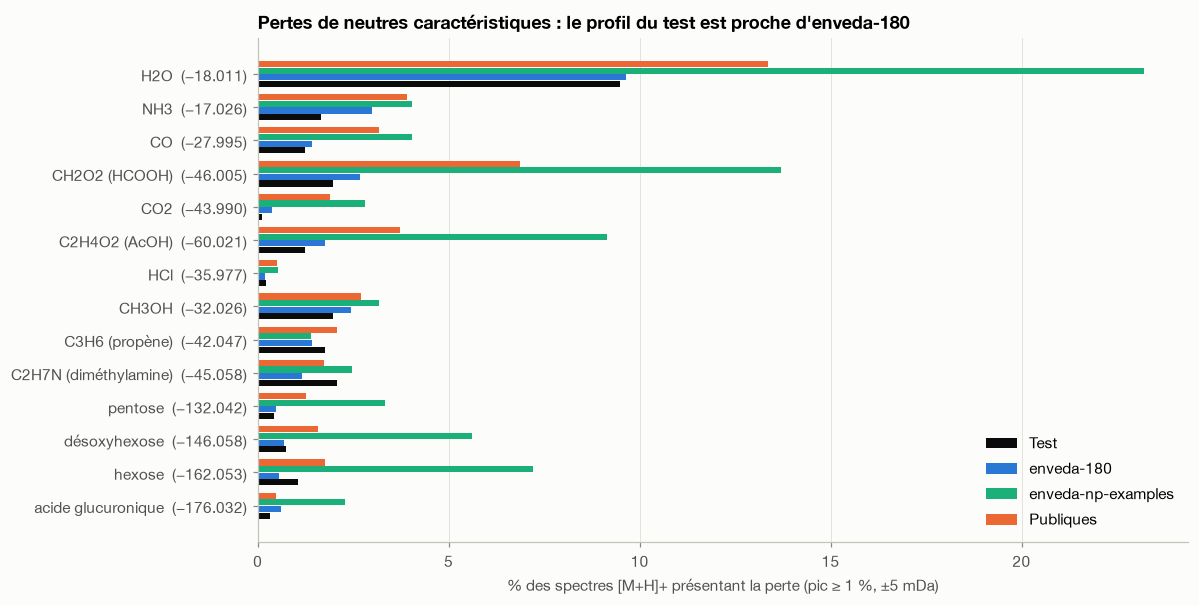

In [27]:
LOSSES = {"H2O": 18.0106, "NH3": 17.0265, "CO": 27.9949, "CH2O2 (HCOOH)": 46.0055, "CO2": 43.9898,
          "C2H4O2 (AcOH)": 60.0211, "HCl": 35.9767, "CH3OH": 32.0262,
          "C3H6 (propène)": 42.0470, "C2H7N (diméthylamine)": 45.0578,
          "pentose": 132.0423, "désoxyhexose": 146.0579, "hexose": 162.0528, "acide glucuronique": 176.0321}

def loss_presence(df, g, tol=0.005):
    out = []
    for mz, I, p in df.select("ms2_mzs", "ms2_normalized_intensities", "precursor_mz").iter_rows():
        mz, I = np.asarray(mz), np.asarray(I); k = (I >= 0.01) & (mz < p - 1)
        L = p - mz[k]
        out.append({n: bool((np.abs(L - m) < tol).any()) for n, m in LOSSES.items()})
    return pl.DataFrame(out).mean().with_columns(pl.lit(g).alias("group"))

pos = lambda df: df.filter(pl.col("adduct") == "[M+H]+")
lp = pl.concat([loss_presence(pos(test), "Test"), loss_presence(pos(npx), "enveda-np-examples"),
                loss_presence(pos(e180.sample(6000, seed=SEED)), "enveda-180"),
                loss_presence(pos(spec.filter(pl.col("group") == "Publiques")).sample(6000, seed=SEED), "Publiques")])

fig, ax = plt.subplots(figsize=(11, 5.6))
names = list(LOSSES); y = np.arange(len(names)); h = 0.2
for i, g in enumerate(GROUPS):
    v = lp.filter(pl.col("group") == g).select(names).row(0)
    ax.barh(y + (1.5 - i) * h, np.array(v) * 100, height=h * 0.92, color=COL[g], label=g)
ax.set_yticks(y, [f"{n}  (−{LOSSES[n]:.3f})" for n in names]); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("% des spectres [M+H]+ présentant la perte (pic ≥ 1 %, ±5 mDa)"); ax.legend(loc="lower right")
ax.set_title("Pertes de neutres caractéristiques : le profil du test est proche d'enveda-180")
plt.tight_layout(); plt.show()

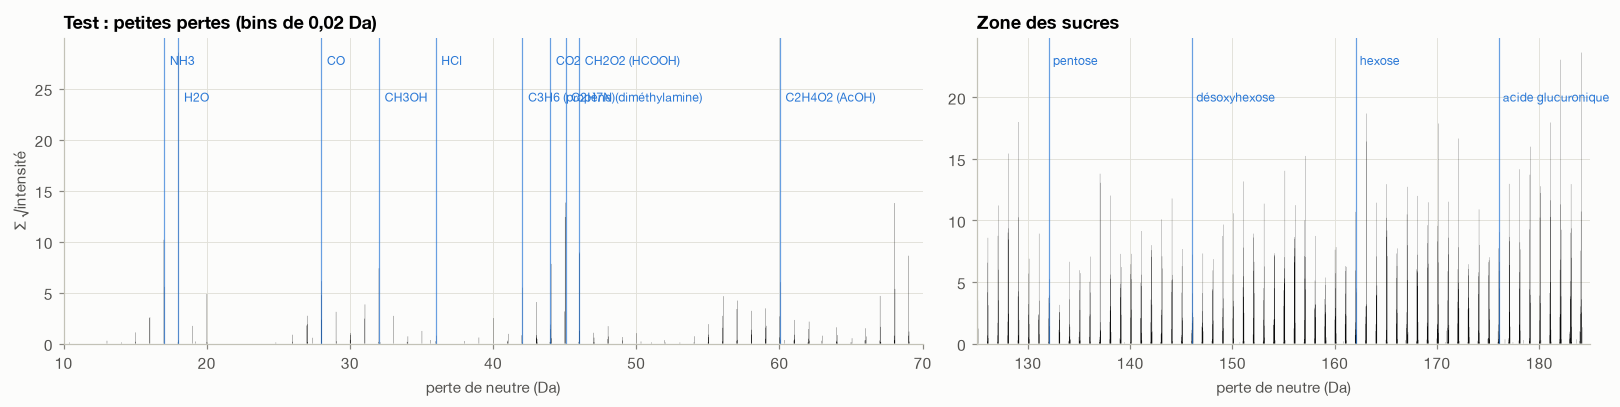

In [28]:
# Spectre de pertes de neutres du test : deux fenêtres (petites pertes / zone des sucres)
L, W = [], []
for mz, I, p in pos(test).select("ms2_mzs", "ms2_normalized_intensities", "precursor_mz").iter_rows():
    mz, I = np.asarray(mz), np.asarray(I); k = (I >= 0.01) & (mz < p - 1)
    L += list(p - mz[k]); W += list(np.sqrt(I[k]))
L, W = np.array(L), np.array(W)
fig, axes = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1.4, 1]})
for ax, (lo, hi) in zip(axes, [(10, 70), (125, 185)]):
    k = (L >= lo) & (L < hi)
    ax.hist(L[k], bins=np.arange(lo, hi, 0.02), weights=W[k], color=INK, histtype="stepfilled")
    ymax = ax.get_ylim()[1]
    for i, (n, m) in enumerate(sorted(LOSSES.items(), key=lambda x: x[1])):
        if lo <= m < hi:
            ax.axvline(m, color=COL["enveda-180"], lw=0.8, alpha=0.7)
            ax.text(m + 0.4, ymax * (0.95 - 0.12 * (i % 2)), n, fontsize=8, color=COL["enveda-180"], va="top")
    ax.set_xlabel("perte de neutre (Da)"); ax.set_xlim(lo, hi)
axes[0].set_ylabel("Σ √intensité"); axes[0].set_title("Test : petites pertes (bins de 0,02 Da)"); axes[1].set_title("Zone des sucres")
plt.tight_layout(); plt.show()

**Ce qu'on retient**
- Les produits naturels d'np-examples se distinguent nettement : pertes de **H2O (23 %), HCOOH, acide acétique et sucres** (hexose 7 %, désoxyhexose 6 %). Ce sont les signatures de molécules hydroxylées, acylées et **glycosylées**.
- Le **test, lui, a un profil proche d'enveda-180** : H2O ~10 %, très peu de sucres (~1 % pour l'hexose), peu de pertes acides. **Le test contient donc peu de glycosides.** Ce sont plutôt des aglycones ou des analogues de type « drug-like ».
- Les pertes les plus fréquentes du test (calculées directement sur les données) sont H2O (18,011), CH3OH (32,026) et **C2H7N (45,058, diméthylamine)**. Cette dernière est la signature des **amines tertiaires**, typiques des alcaloïdes et des molécules drug-like, et cohérente avec les 53 % de N impairs.
- Dans la « zone des sucres », aucun pic ne ressort aux masses des sucres : le peigne régulier (tous les ~1 Da) reflète seulement la distribution des masses de fragments.
- C'est cohérent avec la section 8.1 : **pour la forme des spectres, enveda-180 est la référence**. Les pertes restent rares (< 10 % des spectres pour chacune) : utilisées seules, elles sont des features **creuses mais très spécifiques**.

**Features** : vecteur binaire ou d'intensité des **pertes connues** (~30 pertes), plus un **spectre de pertes binné** comme second canal d'entrée du modèle, à côté du spectre de fragments.

## 9. Espace chimique des cibles (RDKit)

Les SMILES du train sont la **cible**. Avec RDKit, on décrit quelles molécules le modèle apprendra à reconnaître, et on les compare aux molécules attendues en test (produits naturels).

In [29]:
from rdkit import Chem, RDLogger
from rdkit.Chem import Descriptors, rdMolDescriptors as rd
RDLogger.DisableLog("rdApp.*")

mols = meta.group_by("inchikey14").agg(pl.col("normalized_smiles").first(), pl.col("molecular_formula").first(),
                                       pl.col("group").unique().alias("groups"))
mols = mols.with_columns(pl.when(pl.col("groups").list.contains("enveda-np-examples")).then(pl.lit("enveda-np-examples"))
                           .when(pl.col("groups").list.contains("enveda-180")).then(pl.lit("enveda-180"))
                           .otherwise(pl.lit("Publiques")).alias("group"))

f_desc = CACHE / "mol_desc.parquet"
if not f_desc.exists():
    samp = pl.concat([mols.filter(pl.col("group") == "enveda-np-examples"),
                      mols.filter(pl.col("group") == "enveda-180").sample(8000, seed=SEED),
                      mols.filter(pl.col("group") == "Publiques").sample(8000, seed=SEED)])
    rows = []
    for ik, smi, g in samp.select("inchikey14", "normalized_smiles", "group").iter_rows():
        m = Chem.MolFromSmiles(smi)
        if m is None: continue
        sym = [a.GetSymbol() for a in m.GetAtoms()]
        rows.append(dict(inchikey14=ik, group=g, mass=rd.CalcExactMolWt(m), heavy=m.GetNumHeavyAtoms(),
                         rings=rd.CalcNumRings(m), arom_rings=rd.CalcNumAromaticRings(m), fsp3=rd.CalcFractionCSP3(m),
                         stereo=len(Chem.FindMolChiralCenters(m, includeUnassigned=True)), logp=Descriptors.MolLogP(m),
                         nC=sym.count("C"), nN=sym.count("N"), nO=sym.count("O"), nS=sym.count("S"),
                         n_hal=sum(s in ("F", "Cl", "Br", "I") for s in sym), hbd=rd.CalcNumHBD(m)))
    pl.DataFrame(rows).write_parquet(f_desc)
desc = pl.read_parquet(f_desc)
desc.group_by("group").agg(pl.len(), *[pl.col(c).median() for c in ["mass", "heavy", "rings", "arom_rings", "fsp3", "stereo", "nN", "nO", "n_hal", "logp"]])

group,len,mass,heavy,rings,arom_rings,fsp3,stereo,nN,nO,n_hal,logp
str,u32,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""Publiques""",8000,349.179027,25.0,3.0,2.0,0.428571,1.0,2.0,3.0,0.0,3.00156
"""enveda-180""",8000,329.153955,23.0,3.0,2.0,0.444444,1.0,3.0,2.0,0.0,2.34224
"""enveda-np-examples""",250,354.194343,25.0,3.0,1.5,0.465476,2.5,0.0,5.0,0.0,2.4136


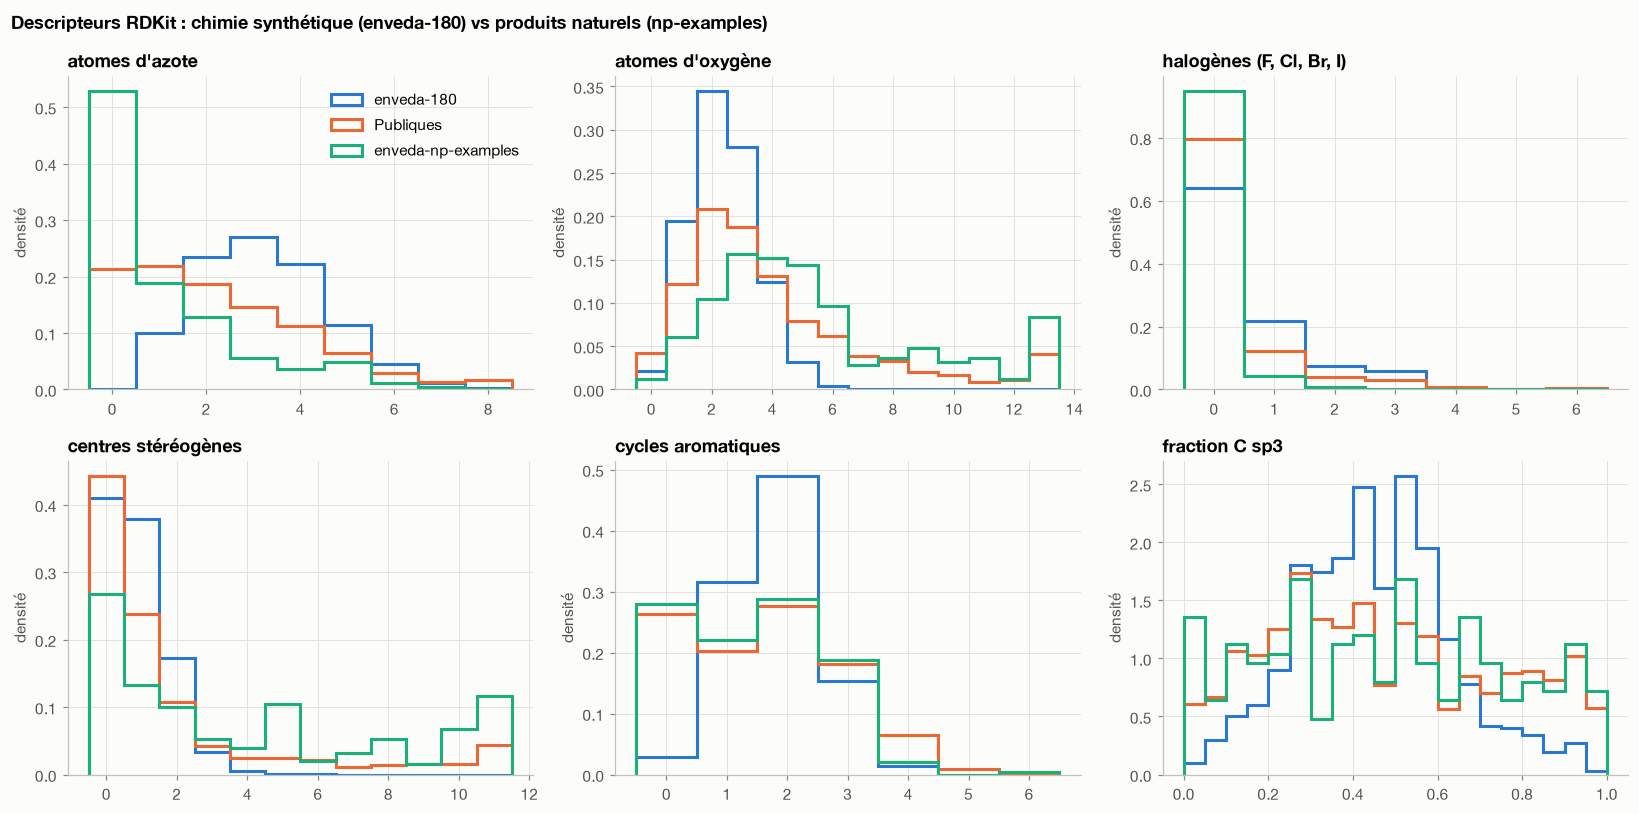

In [30]:
G3 = ["enveda-180", "Publiques", "enveda-np-examples"]
panels = [("nN", "atomes d'azote", np.arange(-0.5, 9.5, 1)), ("nO", "atomes d'oxygène", np.arange(-0.5, 14.5, 1)),
          ("n_hal", "halogènes (F, Cl, Br, I)", np.arange(-0.5, 7.5, 1)), ("stereo", "centres stéréogènes", np.arange(-0.5, 12.5, 1)),
          ("arom_rings", "cycles aromatiques", np.arange(-0.5, 7.5, 1)), ("fsp3", "fraction C sp3", np.linspace(0, 1, 21))]
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5))
for ax, (c, t, b) in zip(axes.ravel(), panels):
    for g in G3:
        v = desc.filter(pl.col("group") == g)[c].to_numpy()
        ax.hist(np.clip(v, b[0], b[-1] - 1e-9), bins=b, density=True, histtype="step", lw=2, color=COL[g], label=g)
    ax.set_title(t); ax.set_ylabel("densité")
axes[0, 0].legend()
fig.suptitle("Descripteurs RDKit : chimie synthétique (enveda-180) vs produits naturels (np-examples)", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

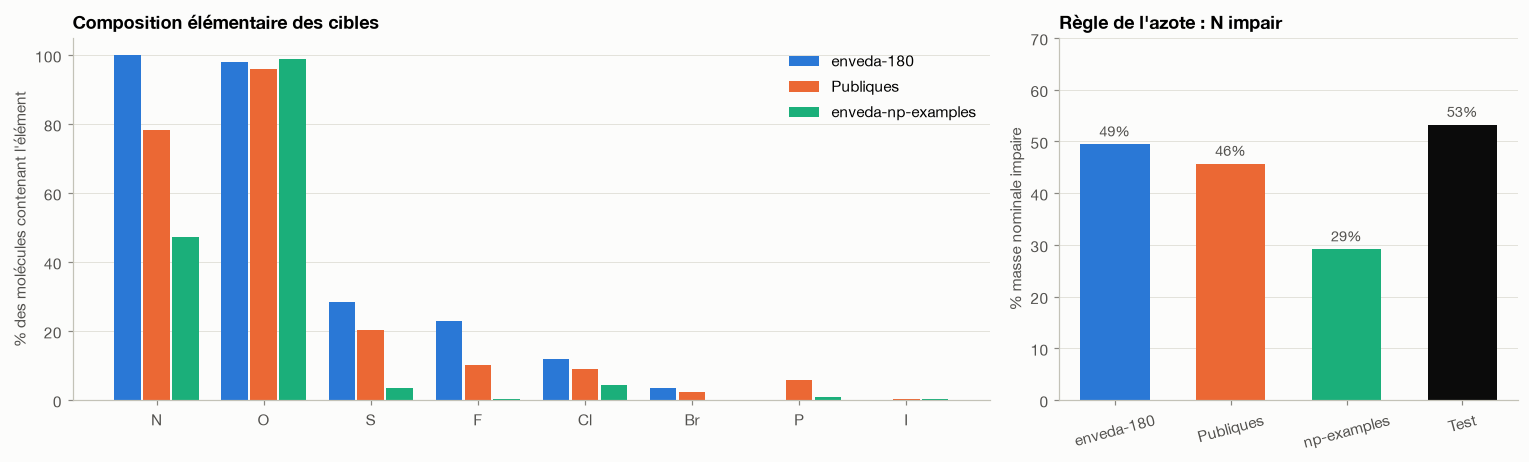

In [31]:
# Éléments présents (train, par molécule unique) -- à partir de la formule brute
el = (mols.with_columns(pl.col("molecular_formula").str.extract_all(r"[A-Z][a-z]?").list.unique().alias("el"))
          .explode("el").group_by("group", "el").len()
          .join(mols.group_by("group").len().rename({"len": "tot"}), on="group")
          .with_columns((pl.col("len") / pl.col("tot")).alias("p")))
elements = ["N", "O", "S", "F", "Cl", "Br", "P", "I"]

# Règle de l'azote : masse nominale impaire  <=>  nombre impair d'atomes N
from rdkit.Chem.rdMolDescriptors import CalcExactMolWt
odd = {g: float((np.round(desc.filter(pl.col("group") == g)["mass"].to_numpy()).astype(int) % 2 == 1).mean()) for g in G3}
odd["Test"] = float((np.round(test_mol["neutral_mass"].to_numpy()).astype(int) % 2 == 1).mean())

fig, (a0, a1) = plt.subplots(1, 2, figsize=(14, 4.3), gridspec_kw={"width_ratios": [2, 1]})
x = np.arange(len(elements)); w = 0.27
for i, g in enumerate(G3):
    v = [el.filter((pl.col("group") == g) & (pl.col("el") == e))["p"].sum() for e in elements]
    a0.bar(x + (i - 1) * w, np.array(v) * 100, width=w * 0.92, color=COL[g], label=g)
a0.set_xticks(x, elements); a0.set_ylabel("% des molécules contenant l'élément"); a0.legend(); a0.grid(axis="x", visible=False)
a0.set_title("Composition élémentaire des cibles")

ks = ["enveda-180", "Publiques", "enveda-np-examples", "Test"]
a1.bar(range(4), [odd[k] * 100 for k in ks], color=[COL[k] for k in ks], width=0.6)
for i, k in enumerate(ks): a1.text(i, odd[k] * 100 + 1.5, f"{odd[k]:.0%}", ha="center", fontsize=9.5, color=INK2)
a1.set_xticks(range(4), ["enveda-180", "Publiques", "np-examples", "Test"], rotation=15); a1.set_ylim(0, 70)
a1.set_ylabel("% masse nominale impaire"); a1.grid(axis="x", visible=False)
a1.set_title("Règle de l'azote : N impair")
plt.tight_layout(); plt.show()

**Ce qu'on retient**
- **enveda-180** contient des molécules médicinales synthétiques : quasiment toutes azotées (souvent 3 N ou plus), **1/3 halogénées**, aromatiques, peu de stéréocentres.
- **np-examples** contient des produits naturels : **la moitié sans azote**, riches en oxygène (5 O en médiane), plus de stéréocentres, peu d'halogènes.
- **Test** : la règle de l'azote, appliquée aux masses de test (seule information chimique observable), donne **53 % de masses impaires**. C'est proche d'enveda-180 (49 %) et loin de np-examples (29 %). Le test contient donc **beaucoup de molécules azotées** : alcaloïdes, ou analogues de produits naturels synthétisés en chimiothèque. Avec les sections 8.1 et 8.2, tous les indicateurs observables placent le test **plus près d'enveda-180 que des exemples de produits naturels**.
- Features **directement calculables en test** : `odd_nominal_mass` (parité du nombre de N), `mass_defect` (un défaut élevé indique une molécule riche en H ; un défaut bas, la présence d'halogènes, de S ou de P).

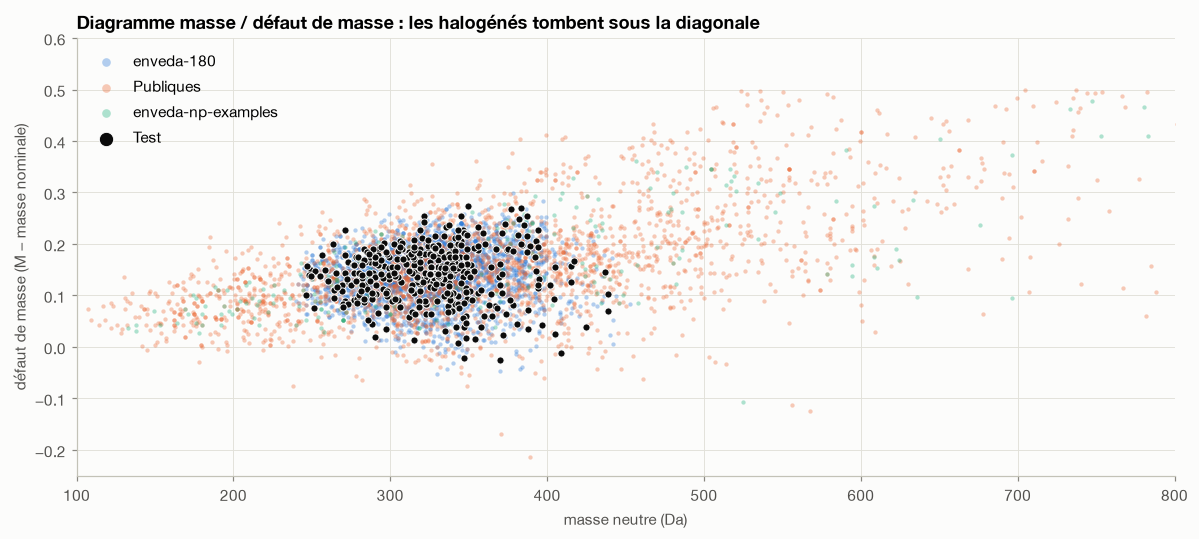

In [32]:
# Défaut de masse = M - masse nominale (arrondi) : évite le repli artificiel autour de 0/1
mol_md = desc.with_columns((pl.col("mass") - pl.col("mass").round(0)).alias("md"))
fig, ax = plt.subplots(figsize=(11, 5))
for g in ["enveda-180", "Publiques", "enveda-np-examples"]:
    v = mol_md.filter(pl.col("group") == g)
    v = v.sample(min(3000, len(v)), seed=SEED)
    ax.scatter(v["mass"], v["md"], s=8, alpha=0.35, color=COL[g], label=g, lw=0)
ax.scatter(test_mol["neutral_mass"], test_mol["neutral_mass"] - test_mol["neutral_mass"].round(0), s=22, color=INK, label="Test", edgecolor=SURF, lw=0.6)
ax.set_xlim(100, 800); ax.set_ylim(-0.25, 0.6); ax.set_xlabel("masse neutre (Da)"); ax.set_ylabel("défaut de masse (M − masse nominale)")
ax.set_title("Diagramme masse / défaut de masse : les halogénés tombent sous la diagonale"); ax.legend(markerscale=2)
plt.tight_layout(); plt.show()

**Lecture** : pour une molécule organique classique (CHNO), le défaut de masse croît avec la masse, car chaque H apporte +0,0078. Les molécules **halogénées** (Cl, Br) ou riches en S et P ont un défaut de masse plus faible, parfois négatif, et se placent **sous la bande principale**. Les molécules de test (points noirs) sont presque toutes dans la bande CHNO. Seuls quelques points tombent près de 0 ou en dessous (candidats Cl, Br ou S, cohérents avec les ~3 % de M+2 forts vus plus haut).

## 10. Ambiguïté isomérique et espace de recherche

**Question** : la masse seule suffit-elle à identifier une molécule ? Combien de structures partagent une même formule ou une même masse ?

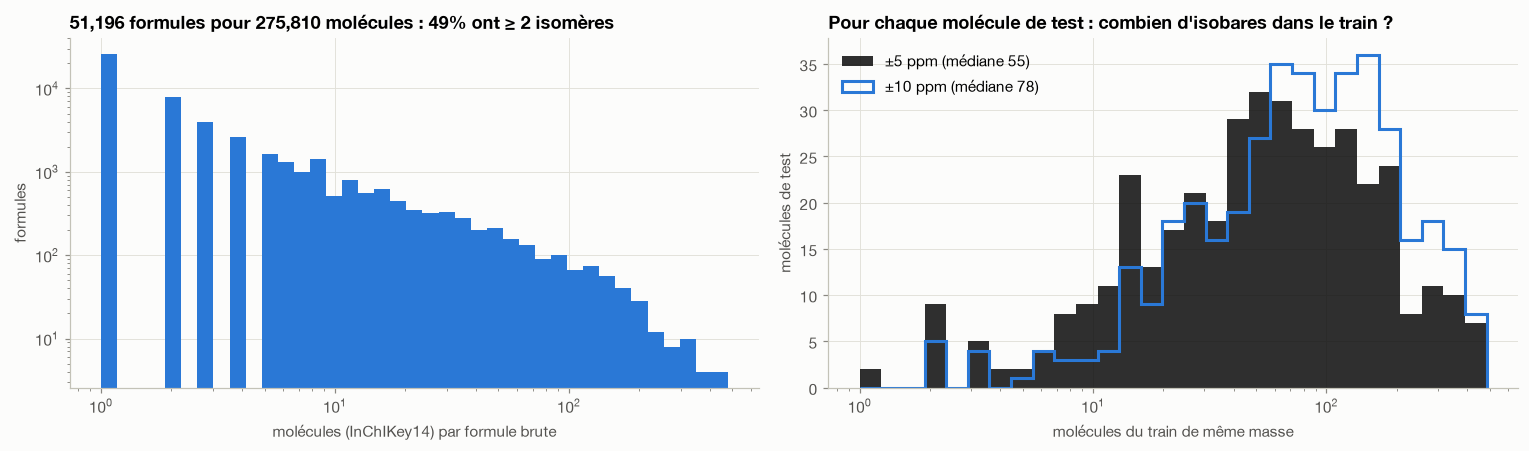

Formules les plus ambiguës :


molecular_formula,len
str,u32
"""C19H24N4O2""",477
"""C18H24N4O2""",463
"""C19H26N4O2""",422
"""C17H22N4O2""",409
"""C18H22N4O2""",380
"""C18H23N3O2""",354
"""C19H23N3O3""",350
"""C18H23N3O3""",350


In [33]:
iso = mols.group_by("molecular_formula").len()
all_mass = []
for smi in mols["normalized_smiles"]:
    m = Chem.MolFromSmiles(smi); all_mass.append(CalcExactMolWt(m) if m else np.nan)
mols = mols.with_columns(pl.Series("mass", all_mass))
arr = np.sort(mols["mass"].drop_nans().to_numpy())

def n_isobars(M, ppm):
    tol = M * ppm * 1e-6
    return np.searchsorted(arr, M + tol) - np.searchsorted(arr, M - tol)
tm = test_mol["neutral_mass"].to_numpy()
iso5, iso10 = n_isobars(tm, 5), n_isobars(tm, 10)

fig, (a0, a1) = plt.subplots(1, 2, figsize=(14, 4.2))
vc = iso["len"].to_numpy()
a0.hist(vc, bins=np.logspace(0, np.log10(vc.max() + 1), 40), color=COL["enveda-180"])
a0.set_xscale("log"); a0.set_yscale("log"); a0.set_xlabel("molécules (InChIKey14) par formule brute"); a0.set_ylabel("formules")
a0.set_title(f"{len(iso):,} formules pour {len(mols):,} molécules : {(vc > 1).mean():.0%} ont ≥ 2 isomères")
a1.hist(iso5, bins=np.logspace(0, np.log10(iso10.max() + 1), 30), histtype="stepfilled", color=INK, alpha=0.85, label=f"±5 ppm (médiane {np.median(iso5):.0f})")
a1.hist(iso10, bins=np.logspace(0, np.log10(iso10.max() + 1), 30), histtype="step", lw=2, color=COL["enveda-180"], label=f"±10 ppm (médiane {np.median(iso10):.0f})")
a1.set_xscale("log"); a1.set_xlabel("molécules du train de même masse"); a1.set_ylabel("molécules de test"); a1.legend()
a1.set_title("Pour chaque molécule de test : combien d'isobares dans le train ?")
plt.tight_layout(); plt.show()
print("Formules les plus ambiguës :"); iso.sort("len", descending=True).head(8)

**Ce qu'on retient**
- 49 % des formules ont au moins 2 isomères. Les plus ambiguës (C19H24N4O2 : 477 structures, C18H24N4O2 : 463…) sont des formules **azotées de chimiothèque** : enveda-180 explore des séries combinatoires d'isomères. **La masse filtre, mais ne discrimine pas** : c'est le spectre MS2 qui départage les isomères.
- Chaque molécule de test a typiquement **~50 isobares dans le train**. Mais le test est inédit (jamais publié), donc la bonne réponse n'est **probablement pas** dans le train. Il faut une **base de candidats externe** (PubChem, COCONUT, etc.) filtrée par masse, ou une **génération de novo**. Le train sert alors à apprendre la fonction de **score spectre ↔ structure**.

## 11. Domain shift dans l'espace des spectres

**Question** : une fois les spectres vectorisés, à quelle source du train le test ressemble-t-il ? On vectorise chaque spectre en bins de 1 Da (0–500, intensité √, pics ≥ 0,5 %, normalisation L2), si bien que le produit scalaire est une **similarité cosinus**. Pour retirer l'effet de l'adduit et de l'énergie, on se limite aux spectres **`[M+H]+` à 40 eV**.

*Remarque* : une ACP sur ces vecteurs creux de 500 dimensions n'explique que ~3 % de variance par axe, elle est donc trompeuse. On utilise plutôt un **t-SNE (métrique cosinus)** sur des groupes de taille équilibrée, complété par une mesure quantitative.

{'enveda-180': 4960, 'Publiques': 774, 'enveda-np-examples': 104, 'Test': 269}


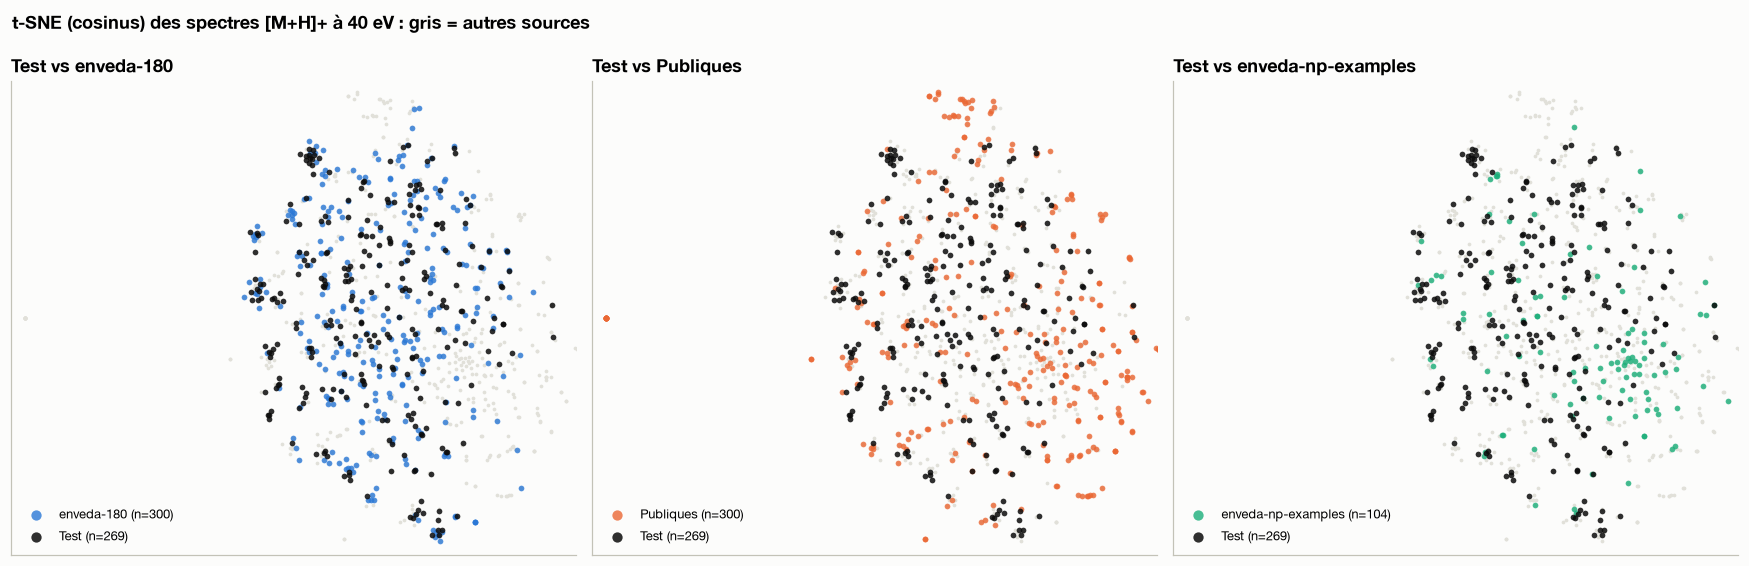

In [34]:
from sklearn.manifold import TSNE

def binned(df, max_mz=500, step=1.0):
    X = np.zeros((len(df), int(max_mz / step)), dtype=np.float32)
    for i, (mz, I) in enumerate(df.select("ms2_mzs", "ms2_normalized_intensities").iter_rows()):
        mz, I = np.asarray(mz), np.asarray(I); k = (mz < max_mz) & (I >= 0.005)
        np.add.at(X[i], (mz[k] / step).astype(int), np.sqrt(I[k]))
    return X / (np.linalg.norm(X, axis=1, keepdims=True) + 1e-9)

sel = lambda df: df.filter((pl.col("adduct") == "[M+H]+") & (pl.col("collision_energy_ev").list.len() == 1)
                           & (pl.col("collision_energy_ev").list.first() == 40.0))
pools = {"enveda-180": sel(spec.filter(pl.col("group") == "enveda-180")),
         "Publiques": sel(spec.filter(pl.col("group") == "Publiques")),
         "enveda-np-examples": sel(npx), "Test": sel(test)}
print({g: len(d) for g, d in pools.items()})
Xp = {g: binned(d) for g, d in pools.items()}

N = 300   # même taille pour chaque source de train : sinon la plus grosse domine visuellement
rng = np.random.default_rng(SEED)
take = {g: (X if g in ("Test", "enveda-np-examples") else X[rng.choice(len(X), N, replace=False)]) for g, X in Xp.items()}
lab = np.concatenate([[g] * len(X) for g, X in take.items()])
Z = TSNE(n_components=2, metric="cosine", perplexity=30, init="pca", random_state=SEED).fit_transform(np.vstack(list(take.values())))

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), sharex=True, sharey=True)
lims = np.percentile(Z, [0.5, 99.5], axis=0)   # recadrage : quelques points isolés écrasent sinon la vue
for ax, g in zip(axes, ["enveda-180", "Publiques", "enveda-np-examples"]):
    ax.set_xlim(lims[0, 0] - 3, lims[1, 0] + 3); ax.set_ylim(lims[0, 1] - 3, lims[1, 1] + 3)
    for gg in ["enveda-180", "Publiques", "enveda-np-examples"]:   # contexte en gris
        ax.scatter(*Z[lab == gg].T, s=6, color=GRID, lw=0)
    ax.scatter(*Z[lab == g].T, s=14, alpha=0.8, color=COL[g], lw=0, label=f"{g} (n={(lab == g).sum()})")
    ax.scatter(*Z[lab == "Test"].T, s=14, color=INK, alpha=0.85, lw=0, label=f"Test (n={(lab == 'Test').sum()})")
    ax.set_title(f"Test vs {g}"); ax.legend(loc="lower left", markerscale=1.8, fontsize=8.5)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("t-SNE (cosinus) des spectres [M+H]+ à 40 eV : gris = autres sources", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()

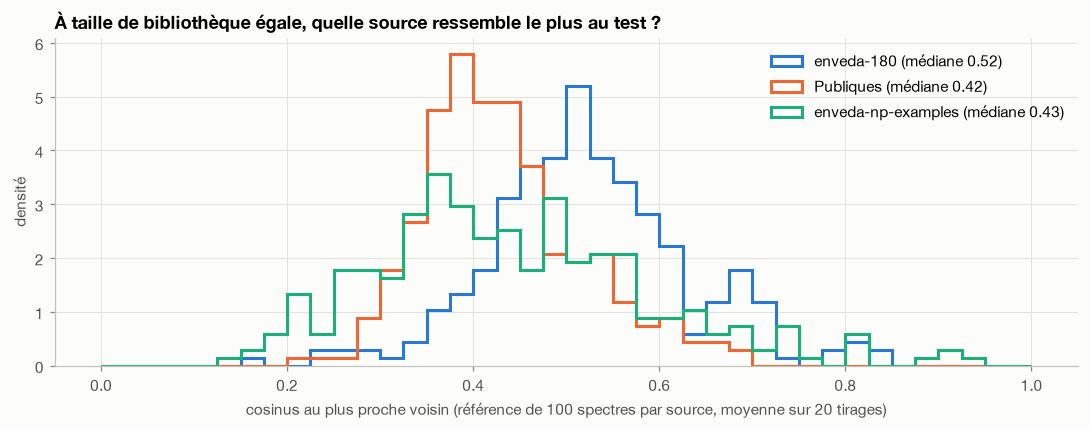

In [35]:
# Mesure équitable : cosinus au plus proche voisin avec une bibliothèque de référence de MÊME taille pour chaque source
# (sinon la source la plus grosse gagne mécaniquement). Moyenne sur 20 tirages.
n_ref = min(len(Xp["enveda-np-examples"]), 100)
res = {}
for g in ["enveda-180", "Publiques", "enveda-np-examples"]:
    res[g] = np.mean([(Xp["Test"] @ Xp[g][rng.choice(len(Xp[g]), n_ref, replace=False)].T).max(axis=1) for _ in range(20)], axis=0)

fig, ax = plt.subplots(figsize=(10, 4))
for g, nn in res.items():
    ax.hist(nn, bins=np.linspace(0, 1, 41), histtype="step", lw=2, color=COL[g], density=True, label=f"{g} (médiane {np.median(nn):.2f})")
ax.set_xlabel(f"cosinus au plus proche voisin (référence de {n_ref} spectres par source, moyenne sur 20 tirages)"); ax.set_ylabel("densité")
ax.legend(loc="upper right"); ax.set_title("À taille de bibliothèque égale, quelle source ressemble le plus au test ?")
plt.tight_layout(); plt.show()

Référence : 4,960 spectres enveda-180 (~0.4% de la source)
cos > 0.8: 46% des spectres de test | parmi eux, même précurseur (±0,01) : 7% | Δprécurseur médian : 30.0 Da
cos > 0.9: 28% des spectres de test | parmi eux, même précurseur (±0,01) : 12% | Δprécurseur médian : 28.6 Da
cos > 0.95: 13% des spectres de test | parmi eux, même précurseur (±0,01) : 25% | Δprécurseur médian : 25.5 Da


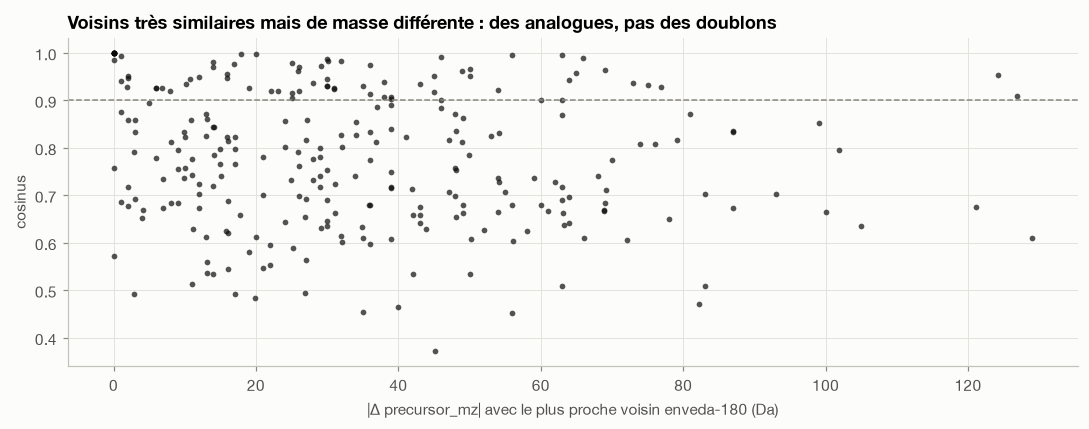

In [36]:
# Quasi-jumeaux : spectres de test ayant un voisin très proche dans enveda-180 (tout l'échantillon disponible)
S = Xp["Test"] @ Xp["enveda-180"].T
nn, j = S.max(axis=1), S.argmax(axis=1)
dprec = np.abs(pools["Test"]["precursor_mz"].to_numpy() - pools["enveda-180"]["precursor_mz"].to_numpy()[j])
print(f"Référence : {len(Xp['enveda-180']):,} spectres enveda-180 (~{len(Xp['enveda-180']) / meta.filter(pl.col('ingest_lib') == 'enveda-180').height:.1%} de la source)")
for t in [0.8, 0.9, 0.95]:
    k = nn > t
    print(f"cos > {t}: {k.mean():.0%} des spectres de test | parmi eux, même précurseur (±0,01) : {(dprec[k] < 0.01).mean():.0%} | Δprécurseur médian : {np.median(dprec[k]):.1f} Da")

fig, ax = plt.subplots(figsize=(10, 4))
ax.scatter(dprec, nn, s=14, color=INK, alpha=0.7, lw=0)
ax.axhline(0.9, color=MUTED, ls="--", lw=1)
ax.set_xlabel("|Δ precursor_mz| avec le plus proche voisin enveda-180 (Da)"); ax.set_ylabel("cosinus")
ax.set_title("Voisins très similaires mais de masse différente : des analogues, pas des doublons")
plt.tight_layout(); plt.show()

**Ce qu'on retient**
- **À taille de référence égale, enveda-180 est la source la plus proche du test**, devant les bibliothèques publiques, puis np-examples. Dans le t-SNE, les spectres de test se répartissent dans les mêmes régions qu'enveda-180, alors qu'une partie des spectres publics forme des îlots sans test. Les produits naturels d'np-examples se regroupent dans une zone où le test est peu présent.
- Même avec un **échantillon minuscule d'enveda-180** (~0,4 % de la source à 40 eV), **plus d'un quart (28 %) des spectres de test** ont un voisin à cosinus > 0,9**. Mais ce voisin a presque toujours un **précurseur différent** (Δ médian ~ 30 Da) : c'est un **analogue structural** qui partage le même squelette, donc les mêmes fragments, avec un substituant différent.
- Implications :
  1. **enveda-180 contient très probablement des analogues des molécules de test** : un modèle qui apprend à relier fragments et sous-structures sur enveda-180 devrait bien se transférer.
  2. Une recherche par plus proche voisin spectral peut **proposer un squelette**, mais la bonne masse doit être obtenue par **modification du substituant** (approche de type analog search ou génération guidée).
  3. Des features de **différence de masse avec le voisin** (Δ = CH2, O, OH→OCH3…) deviennent pertinentes.

## 12. Synthèse et implications pour le feature engineering

### Constat
| Dimension | Train | Test | Conséquence |
|---|---|---|---|
| Sources | 11 bibliothèques hétérogènes | Enveda, inédit | Pondérer ou filtrer par source ; **enveda-180 = source la plus proche** |
| Instrument | 83 libellés, 45 % timsTOF | 100 % timsTOF | Feature `instrument_group` ou entraînement ciblé |
| Adduits | 121 (dont dimères) | 7 mono-chargés | Garder les 7 adduits du test |
| Énergie | eV / NCE / V / inconnue | 20, 40, 60, fusion | Conditionner sur la CE |
| Masse | 100 à > 1 000 Da | 245–440 Da | Restreindre la plage |
| Pics | médiane 42 (publiques filtrées) | médiane 230, même profil qu'enveda-180 | Débruitage top-k + seuil, identique train/test |
| Chimie | synthétique N/halogénée + publique | ~53 % N impair, peu de glycosides, peu d'halogènes | Proche d'enveda-180 ; np-examples = proxy imparfait |
| Similarité spectrale | – | analogues fréquents dans enveda-180 (cos > 0,9, Δm ≠ 0) | Recherche d'analogues + features Δ de masse |
| Réponses | 276 k molécules | probablement hors train | Base de candidats externe + scoring |

### Nettoyage
1. `adduct ∈ {7 adduits du test}` ; retirer les `[2M…]`
2. `|precursor_error_ppm| ≤ 20` ; `precursor_mz ∈ [~150, ~700]` pour l'entraînement ciblé
3. Pondérer chaque spectre par `1 / n_spectres(molécule)`
4. Harmoniser `instrument_type` (7 familles) ; encoder `ce_missing`

### Features par spectre
- **Méta** : `neutral_mass`, `mass_defect`, `odd_nominal_mass`, one-hot `adduct`, `polarity`, `ce_min/ce_max/ce_is_merged`, `instrument_group`
- **Résumé du spectre** (après seuil de 0,5–1 % et top-k ≈ 50) : `n_peaks`, `entropy`, `prec_frac`, `mz_mean_rel`, `n_above_prec`
- **Isotopes** : ratio M+1/M (≈ nombre de C), M+2/M (Cl, Br, S)
- **Vecteurs** : spectre binné (√I, L2) et **spectre de pertes de neutres** binné ; indicateurs des pertes connues (H2O, CO, HCOOH, sucres…)

### Features par molécule (agrégation test)
- Fusion ou moyenne des spectres de même polarité ; `has_pos`, `has_neg`, `n_spectra` ; présence de l'adduit formiate (indice d'un groupe acide)

### Représentation de la cible
- Empreintes Morgan (ECFP4, 2 048 bits) et MACCS pour une approche **spectre → empreinte → classement des candidats** ; descripteurs (nN, nO, cycles) comme **tâches auxiliaires**.

### Validation
- **GroupKFold sur `inchikey14`**, ou découpage par **squelette (scaffold)** ; jeu « proche du test » = **enveda-180 restreint** (7 adduits, 245–460 Da, CE 20/40/60/fusion, split par scaffold), complété par **enveda-np-examples** pour vérifier la robustesse sur des produits naturels ; métrique = **MRR@25 sur InChIKey14 après canonicalisation des tautomères**.